In [1]:
# Importing the Dependencies

import pandas as pd
import numpy as np
import time

import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns

from scipy import stats
from scipy.stats import norm, skew
from scipy.special import boxcox1p
from scipy.stats import boxcox_normmax

In [2]:
import sklearn

from sklearn import preprocessing
from sklearn.preprocessing import StandardScaler

from sklearn import metrics
from sklearn.metrics import roc_curve, auc, roc_auc_score
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.metrics import average_precision_score, precision_recall_curve

from sklearn.model_selection import train_test_split
from sklearn.model_selection import StratifiedKFold
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV


In [3]:
from sklearn.linear_model import Ridge, Lasso, LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegressionCV
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import AdaBoostClassifier
from sklearn.ensemble import RandomForestClassifier


In [4]:
import xgboost as xgb
from xgboost import XGBClassifier
from xgboost import plot_importance
from sklearn.ensemble import AdaBoostClassifier

# to ignore warnings
import warnings
warnings.filterwarnings("ignore")

# EXPLORATORY DATA ANALYSYS

In [2]:
#Importing the Dataset
df = pd.read_csv('creditcard.csv')
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [6]:
df.shape


(284807, 31)

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     28

In [8]:
df.describe()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
count,284807.000000,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,...,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,284807.000000,284807.000000
mean,94813.859575,1.175161e-15,3.384974e-16,-1.379537e-15,2.094852e-15,1.021879e-15,1.494498e-15,-5.620335e-16,1.149614e-16,-2.414189e-15,...,1.628620e-16,-3.576577e-16,2.618565e-16,4.473914e-15,5.109395e-16,1.686100e-15,-3.661401e-16,-1.227452e-16,88.349619,0.001727
std,47488.145955,1.958696e+00,1.651309e+00,1.516255e+00,1.415869e+00,1.380247e+00,1.332271e+00,1.237094e+00,1.194353e+00,1.098632e+00,...,7.345240e-01,7.257016e-01,6.244603e-01,6.056471e-01,5.212781e-01,4.822270e-01,4.036325e-01,3.300833e-01,250.120109,0.041527
min,0.000000,-5.640751e+01,-7.271573e+01,-4.832559e+01,-5.683171e+00,-1.137433e+02,-2.616051e+01,-4.355724e+01,-7.321672e+01,-1.343407e+01,...,-3.483038e+01,-1.093314e+01,-4.480774e+01,-2.836627e+00,-1.029540e+01,-2.604551e+00,-2.256568e+01,-1.543008e+01,0.000000,0.000000
25%,54201.500000,-9.203734e-01,-5.985499e-01,-8.903648e-01,-8.486401e-01,-6.915971e-01,-7.682956e-01,-5.540759e-01,-2.086297e-01,-6.430976e-01,...,-2.283949e-01,-5.423504e-01,-1.618463e-01,-3.545861e-01,-3.171451e-01,-3.269839e-01,-7.083953e-02,-5.295979e-02,5.600000,0.000000
50%,84692.000000,1.810880e-02,6.548556e-02,1.798463e-01,-1.984653e-02,-5.433583e-02,-2.741871e-01,4.010308e-02,2.235804e-02,-5.142873e-02,...,-2.945017e-02,6.781943e-03,-1.119293e-02,4.097606e-02,1.659350e-02,-5.213911e-02,1.342146e-03,1.124383e-02,22.000000,0.000000
75%,139320.500000,1.315642e+00,8.037239e-01,1.027196e+00,7.433413e-01,6.119264e-01,3.985649e-01,5.704361e-01,3.273459e-01,5.971390e-01,...,1.863772e-01,5.285536e-01,1.476421e-01,4.395266e-01,3.507156e-01,2.409522e-01,9.104512e-02,7.827995e-02,77.165000,0.000000
max,172792.000000,2.454930e+00,2.205773e+01,9.382558e+00,1.687534e+01,3.480167e+01,7.330163e+01,1.205895e+02,2.000721e+01,1.559499e+01,...,2.720284e+01,1.050309e+01,2.252841e+01,4.584549e+00,7.519589e+00,3.517346e+00,3.161220e+01,3.384781e+01,25691.160000,1.000000


In [9]:
# Checking the class distribution of the targetr variable
df['Class'].value_counts()

Class
0    284315
1       492
Name: count, dtype: int64

Class
0    99.827251
1     0.172749
Name: Class, dtype: float64


<Axes: ylabel='Class'>

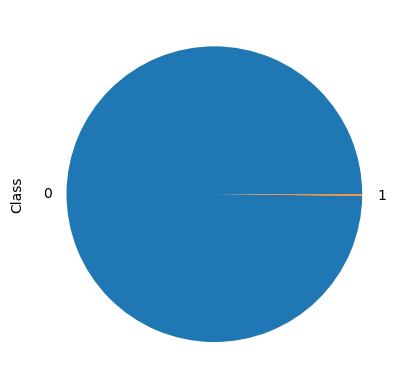

In [10]:
print((df.groupby('Class')['Class'].count()/df['Class'].count()) * 100)
((df.groupby('Class')['Class'].count()/df['Class'].count()) * 100).plot.pie()

In [11]:
# checking the % distributoiin of normal vs fraud
classes = df['Class'].value_counts()
normal_share = classes[0]/df['Class'].count() * 100
fraud_share = classes[1]/df['Class'].count() * 100

print(normal_share)
print(fraud_share)

99.82725143693798
0.1727485630620034


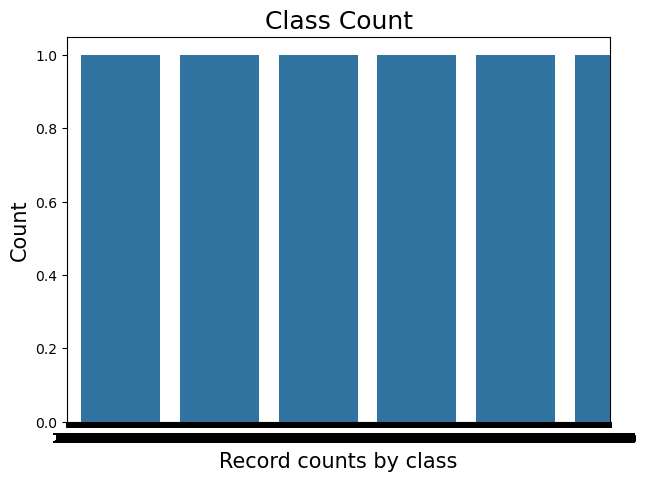

In [12]:
# creating a bar plot for the number and percentage of fraudlent vs non-fraudlent transaction
plt.figure(figsize=(7,5))
sns.countplot(df['Class'])
plt.title("Class Count", fontsize = 18)
plt.xlabel("Record counts by class", fontsize = 15)
plt.ylabel("Count", fontsize=15)
plt.show()

In [13]:
# checking the correlation
corr = df.corr()
corr

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
Time,1.000000,1.173963e-01,-1.059333e-02,-4.196182e-01,-1.052602e-01,1.730721e-01,-6.301647e-02,8.471437e-02,-3.694943e-02,-8.660434e-03,...,4.473573e-02,1.440591e-01,5.114236e-02,-1.618187e-02,-2.330828e-01,-4.140710e-02,-5.134591e-03,-9.412688e-03,-0.010596,-0.012323
V1,0.117396,1.000000e+00,4.188326e-16,-1.164018e-15,-9.082889e-16,2.085924e-17,-6.343731e-16,-1.018099e-15,-2.557889e-16,-1.347621e-16,...,-2.444306e-16,-4.201199e-16,6.217312e-16,-4.385333e-17,-9.832396e-16,-1.745526e-17,1.196577e-16,2.108702e-15,-0.227709,-0.101347
V2,-0.010593,4.188326e-16,1.000000e+00,3.140164e-16,-1.125909e-15,5.230686e-16,2.781752e-16,1.857398e-16,-5.698764e-17,2.006267e-17,...,-8.277282e-17,1.547272e-16,1.668081e-16,1.577058e-17,-4.530958e-16,1.984817e-16,-4.938067e-16,-5.182198e-16,-0.531409,0.091289
V3,-0.419618,-1.164018e-15,3.140164e-16,1.000000e+00,4.644369e-16,-5.483554e-17,1.627805e-15,5.239200e-16,-1.297365e-15,5.725902e-16,...,5.931009e-17,-1.115726e-15,-5.063673e-16,5.605700e-19,-1.118857e-15,-1.389572e-16,1.058098e-15,9.792787e-16,-0.210880,-0.192961
V4,-0.105260,-9.082889e-16,-1.125909e-15,4.644369e-16,1.000000e+00,-1.722056e-15,-7.565957e-16,-4.188169e-16,5.645256e-16,6.873528e-16,...,-1.862123e-16,-3.949686e-17,9.564529e-17,1.569977e-16,6.026069e-16,-4.237973e-16,4.577343e-17,-3.888959e-18,0.098732,0.133447
V5,0.173072,2.085924e-17,5.230686e-16,-5.483554e-17,-1.722056e-15,1.000000e+00,2.208263e-16,2.691713e-16,7.396815e-16,7.178142e-16,...,-3.990893e-16,1.277735e-16,-8.760100e-18,-1.142295e-15,5.021165e-16,4.450164e-16,6.538203e-16,-3.301835e-18,-0.386356,-0.094974
V6,-0.063016,-6.343731e-16,2.781752e-16,1.627805e-15,-7.565957e-16,2.208263e-16,1.000000e+00,1.213776e-16,-1.030439e-16,4.234240e-16,...,5.551919e-17,5.756004e-18,9.443837e-17,-1.070899e-15,4.568884e-16,-1.402561e-16,-4.500879e-16,2.493919e-16,0.215981,-0.043643
V7,0.084714,-1.018099e-15,1.857398e-16,5.239200e-16,-4.188169e-16,2.691713e-16,1.213776e-16,1.000000e+00,3.549393e-16,1.125386e-15,...,-2.122235e-16,-8.840620e-16,-4.458969e-16,9.812896e-18,-2.881866e-16,-9.494990e-16,-1.723845e-15,-2.921030e-16,0.397311,-0.187257
V8,-0.036949,-2.557889e-16,-5.698764e-17,-1.297365e-15,5.645256e-16,7.396815e-16,-1.030439e-16,3.549393e-16,1.000000e+00,4.340695e-16,...,3.830431e-16,2.065947e-16,6.910016e-17,-9.701203e-17,-4.609097e-16,-1.777597e-16,1.280491e-16,-6.187506e-16,-0.103079,0.019875
V9,-0.008660,-1.347621e-16,2.006267e-17,5.725902e-16,6.873528e-16,7.178142e-16,4.234240e-16,1.125386e-15,4.340695e-16,1.000000e+00,...,1.874693e-16,-6.976879e-16,-5.221067e-16,-1.449529e-16,6.679328e-16,-8.154251e-16,-6.111140e-17,1.106537e-15,-0.044246,-0.097733


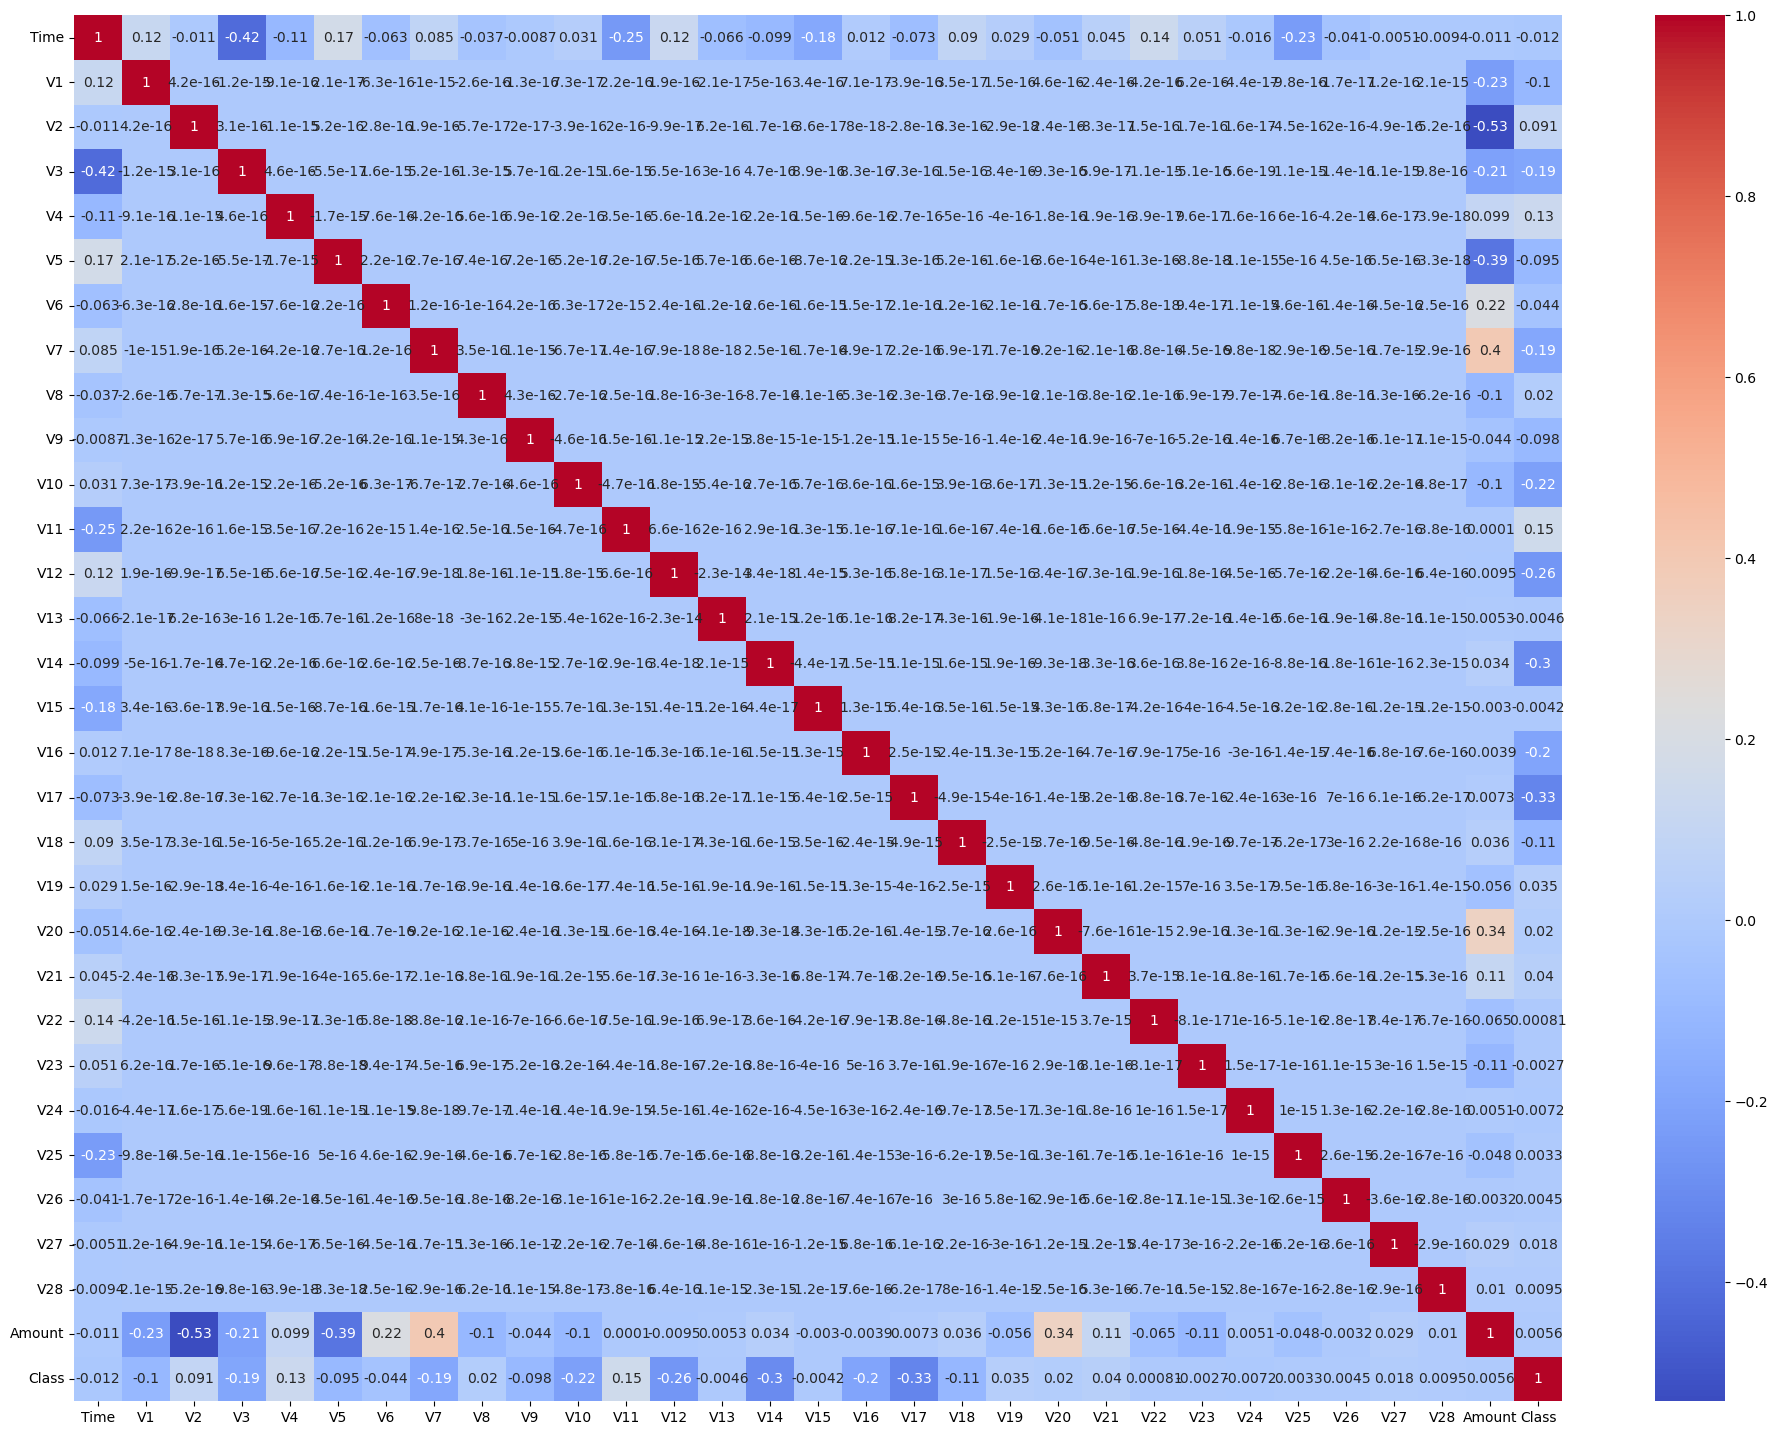

In [14]:
# Cheking the correlation in heatmap
plt.figure(figsize=(24,18))

sns.heatmap(corr, cmap="coolwarm", annot=True)
plt.show()
            

In [15]:
# As time is given in realtive fashion, we are using pandas. Timedelta which represents a duration, the difference between two 
Delta_Time = pd.to_timedelta(df['Time'], unit='s')

# Create derived columns Mins and hours
df['Time_Day'] = (Delta_Time.dt.components.days).astype(int)
df['Time_Hour'] = (Delta_Time.dt.components.hours).astype(int)
df['Time_Min'] = (Delta_Time.dt.components.minutes).astype(int)

In [16]:
# Drop unnecessary columns
# We will drop Time, as we have derived the Day/Hour/Minutes from time column
df.drop('Time', axis = 1, inplace = True)
# we will keep only derived column hour, as day/minutes might not be very useful
df.drop(['Time_Day', 'Time_Min'], axis = 1, inplace = True)

# SPLITTING THE DATA INTO TRAIN & TEST DATA

In [17]:
# Splitting the dataset into X & Y 
y = df['Class']
X = df.drop(['Class'], axis = 1)


In [18]:
# checking rows of head
X.head()

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Time_Hour
0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,0.090794,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,-0.166974,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,0.207643,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,-0.054952,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,0.753074,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [19]:
# Checking rows of y
y.head()

0    0
1    0
2    0
3    0
4    0
Name: Class, dtype: int64

In [20]:
# Splitting the dataset using train test split
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=100, test_size = 0.20)

In [21]:
# Checking the spread of data post split
print(np.sum(y))
print(np.sum(y_train))
print(np.sum(y_test))

492
396
96


## Plotting distribution of a variable

In [22]:
# Accumulating all the column names under one variable
cols = list(X.columns.values)

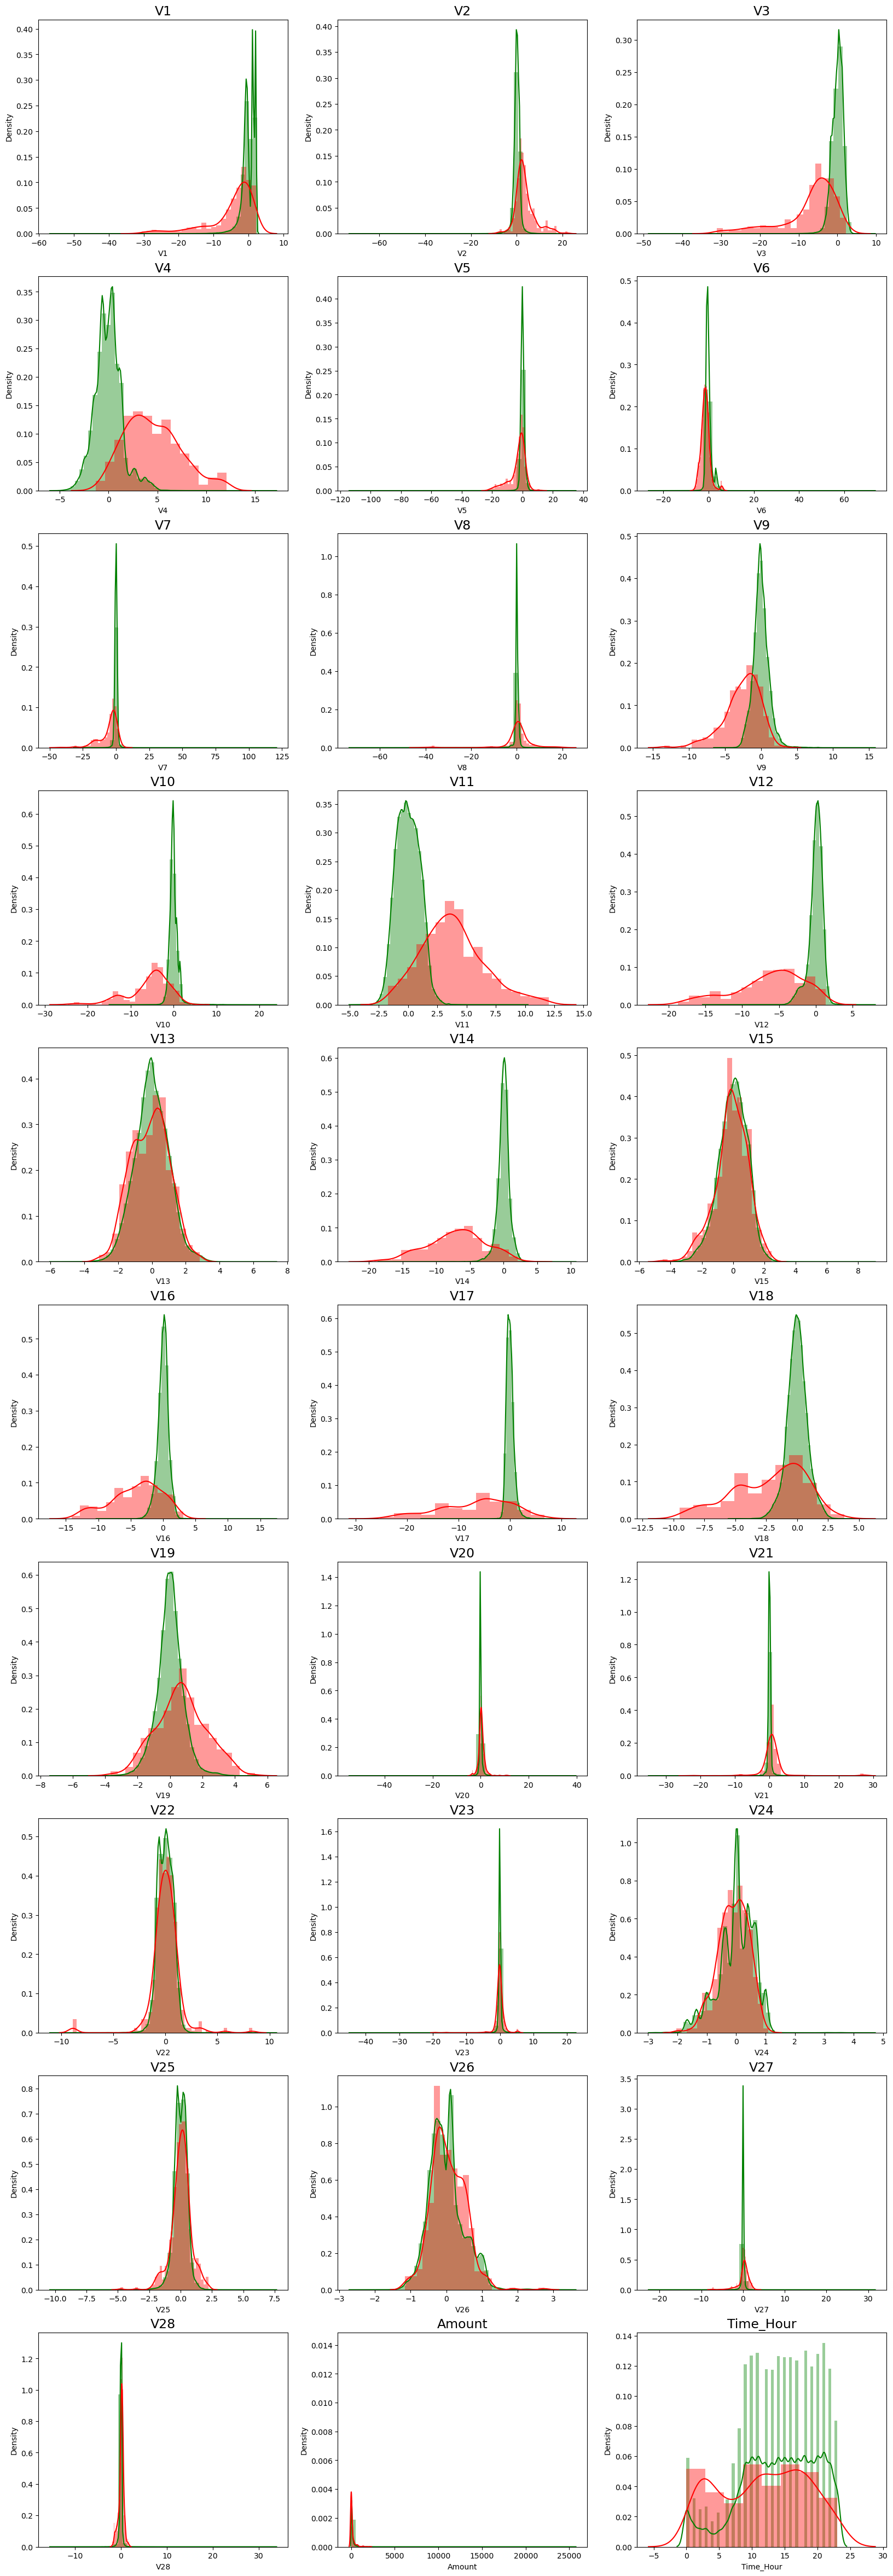

In [23]:
# plot the histogram of a variable from the dataset to see the skewness
normal_records = df.Class == 0 
fraud_records = df.Class == 1

plt.figure(figsize=(20, 60))
for n, col in enumerate(cols):
    plt.subplot(10, 3, n+1)
    sns.distplot(X[col][normal_records], color = 'green')
    sns.distplot(X[col][fraud_records], color='red')
    plt.title(col, fontsize=17)
plt.show()

## Model building

In [24]:
# Create a dataframe to store results
df_Results = pd.DataFrame(columns=['Methodology', 'Model', 'Accuracy', 'roc_value', 'threshold'])


In [25]:
# Created a common function to plot confusion matrix
def Plot_confusion_matrix(y_test, pred_test):
    cm = confusion_matrix(y_test, pred_test)
    plt.clf()
    plt.imshow(cm, interpolation='nearest', cmap=plt.cm.Accent)
    categoryNames = ['Non-Fraudalent', 'Fraudalent']
    plt.title('Confusion Matrix - Test Data')
    plt.ylabel('True label')
    plt.xlabel('Predicted label')
    ticks = np.arange(len(categoryNames))
    plt.xticks(ticks, categoryNames, rotation=45)
    plt.yticks(ticks, categoryNames)
    s = [['TN', 'FP'], ['FN', 'TP']]

    for i in range(2):
        for j in range(2):
            plt.text(j,i, str(s[i][j])+" = "+str(cm[i][j]), fontsize=12)
    plt.show()    

In [26]:
from sklearn import linear_model
from sklearn.model_selection import KFold

## Created a common function to fit and poredict on a logistic Regression model for both l1 and l2
def buildAndRunLogisticModels(df_Results, Methodology, X_train, y_train, X_test, y_test):
# Logistic Regression
 
 num_C = list(np.power(10.0, np.arange(-10, 10)))
 cv_num = KFold(n_splits=10, shuffle=True, random_state=42)

 searchCV_l2 = linear_model.LogisticRegressionCV(
        Cs= num_C
        ,penalty ='l2'
        ,scoring='roc_auc'
        ,cv=cv_num
        ,random_state=42
        ,max_iter=10000
        ,fit_intercept=True
        ,solver='newton-cg'
        ,tol=10
    )

 searchCV_l1 = linear_model.LogisticRegressionCV(
        Cs=num_C
        ,penalty='l1'
        ,scoring='roc_auc'
        ,cv=cv_num
        ,random_state=42
        ,max_iter=10000
        ,fit_intercept=True
        ,solver='liblinear'
        ,tol=10
    )

 searchCV_l1.fit(X_train, y_train)
 searchCV_l2.fit(X_train, y_train)
 print('Max auc_roc for l1:', searchCV_l1.scores_[1].mean(axis=0).max())
 print('Max auc_roc for l2:', searchCV_l2.scores_[1].mean(axis=0).max())

 print("Parameters for l1 regularisations")
 print(searchCV_l1.coef_)
 print(searchCV_l1.intercept_)
 print(searchCV_l1.scores_)

 print("Parameters for l2 regularisations")
 print(searchCV_l2.coef_)
 print(searchCV_l2.intercept_)
 print(searchCV_l2.scores_)

#find predicted values
 y_pred_l1 = searchCV_l1.predict(X_test)
 y_pred_l2 = searchCV_l2.predict(X_test)

#find predicted probabilities
 y_pred_probs_l1 = searchCV_l1.predict_proba(X_test)[:,1]
 y_pred_probs_l2 = searchCV_l2.predict_proba(X_test)[:,1]

# Accuracy of L2/L1 models
 Accuracy_l2 = metrics.accuracy_score(y_pred=y_pred_l2, y_true=y_test)
 Accuracy_l1 = metrics.accuracy_score(y_pred=y_pred_l1, y_true=y_test)

 print("Accuracy pf Logistic model with l2 regularisation : {0}".format(Accuracy_l2))
 print("Confusion Matrix")
 Plot_confusion_matrix(y_test, y_pred_l2)
 print("classification Report")
 print(classification_report(y_test, y_pred_l2))

 print("Accuracy pf Logistic model with l1 regularisation : {0}".format(Accuracy_l1))
 print("Confusion Matrix")
 Plot_confusion_matrix(y_test, y_pred_l1)
 print("classification Report")
 print(classification_report(y_test, y_pred_l1))

 l2_roc_value = roc_auc_score(y_test, y_pred_probs_l2)
 print("l2 roc_value: {0}" .format(l2_roc_value))
 fpr, tpr, thresholds = metrics.roc_curve(y_test, y_pred_probs_l2)
 threshold = thresholds[np.argmax(tpr-fpr)]
 print("l2 threshold: {0}".format(threshold))

 roc_auc = metrics.auc(fpr, tpr)
 print("ROC for the test dataset", '{:.1%}'.format(roc_auc))
 plt.plot(fpr, tpr, label= "Test, auc="+str(roc_auc))
 plt.legend(loc=4)
 plt.show()

 Methodology = "Baseline" 

 df_Results = pd.concat([
             df_Results,(pd.DataFrame({
                 'Methodology': Methodology, 
                 'Model': 'Logistic Regression with L2 Regularisation', 
                 'Accuracy': Accuracy_l2, 
                 'roc_value': l2_roc_value, 
                 'threshold': threshold}, 
                 index=[0]))], ignore_index=True) 

 l1_roc_value = roc_auc_score(y_test, y_pred_probs_l1)
 print("l1 roc_value: {0}" .format(l1_roc_value))
 fpr, tpr, thresholds = metrics.roc_curve(y_test, y_pred_probs_l1)
 threshold = thresholds[np.argmax(tpr-fpr)]
 print("l1 threshold: {0}".format(threshold))                                          

 roc_auc = metrics.auc(fpr, tpr)
 print("ROC for the test dataset", '{:.1%}'.format(roc_auc))
 plt.plot(fpr, tpr, label= "Test, auc="+str(roc_auc))
 plt.legend(loc=4)
 plt.show()

 df_Results = pd.concat([
             df_Results,(pd.DataFrame({
                 'Methodology': Methodology, 
                 'Model': 'Logistic Regression with L1 Regularisation', 
                 'Accuracy': Accuracy_l2, 
                 'roc_value': l2_roc_value, 
                 'threshold': threshold},
                 index=[0]))], ignore_index=True)
 return df_Results    

In [27]:
#Created a common function to fit and predict on a KNN model
def buildAndRunKNNModels(df_Results, Methodology, X_train, y_train, X_test, y_test):

    #create KNN model and fit the model with train dataset
    knn = KNeighborsClassifier(n_neighbors = 5, n_jobs=16)
    knn.fit(X_train, y_train)
    score = knn.score(X_test, y_test)
    print("model score")
    print(score)

    #Accuracy
    y_pred = knn.predict(X_test)
    KNN_Accuracy = metrics.accuracy_score(y_pred=y_pred, y_true=y_test)
    print("Confusion Matrix")
    Plot_confusion_matrix(y_test, y_pred)
    print("Classification Report")
    print(classification_report(y_test, y_pred))

    knn_probs = knn.predict_proba(X_test)[:, 1]

    # Calculate roc auc
    knn_roc_value = roc_auc_score(y_test, knn_probs)
    print("KNN roc_value: {0}" .format(knn_roc_value))
    fpr, tpr, thresholds = metrics.roc_curve(y_test, knn_probs)
    threshold = thresholds[np.argmax(tpr-fpr)]
    print("KNN threshold: {0}".format(threshold))

    roc_auc = metrics.auc(fpr, tpr)
    print("ROC for the test dataset", '{:.1%}'.format(roc_auc))
    plt.plot(fpr, tpr, label="Test, auc="+str(roc_auc))
    plt.legend(loc=4)
    plt.show()

    df_Results = pd.concat([
                df_Results,(pd.DataFrame({
                    'Methodology': Methodology, 
                    'Model': 'KNN',
                    'Accuracy': score,
                    'roc_value': knn_roc_value,
                    'threshold': threshold},
                    index = [0]))], ignore_index=True)

    return df_Results    

In [28]:
#Created a common function to fit and predict on a Tree models for both gini and entropy criteria

def buildAndRunTreeModels(df_Results, Methodology, X_train, y_train, X_test, y_test):
    #Evaluate Decision Tree model with 'gini' & 'entropy'
    criteria = ['gini', 'entropy']
    scores = {}

    for c in criteria:
        dt = DecisionTreeClassifier(criterion = c, random_state=42)
        dt.fit(X_train, y_train)
        y_pred = dt.predict(X_test)
        test_score = dt.score(X_test, y_test)
        tree_preds = dt.predict_proba(X_test)[:, 1]
        tree_roc_value = roc_auc_score(y_test, tree_preds)
        scores = test_score
        print(c + " score: {0}" .format(test_score))
        print("Confusion Matrix")
        Plot_confusion_matrix(y_test, y_pred)
        print("classification Report")
        print(classification_report(y_test, y_pred))
        print(c + " tree_roc_value: {0}" .format(tree_roc_value))
        fpr, tpr, thresholds = metrics.roc_curve(y_test, tree_preds)
        threshold = thresholds[np.argmax(tpr-fpr)]
        print("Tree threshold: {0}".format(threshold))
        roc_auc = metrics.auc(fpr, tpr)
        print("ROC for the test dataset", '{:.1%}'.format(roc_auc))
        plt.plot(fpr, tpr, label="Test, auc="+str(roc_auc))
        plt.legend(loc=4)
        plt.show()

        df_Results = pd.concat([
                df_Results,(pd.DataFrame({
                    'Methodology': Methodology, 
                    'Model': 'Tree Model with {0} criteria'.format(c),
                    'Accuracy': test_score,
                    'roc_value': tree_roc_value,
                    'threshold': threshold},
                    index = [0]))], ignore_index=True)

        return df_Results         

In [29]:
# Created a common funtion to fit and predict on a Random Forest Model
def buildAndRunRandomForestModels(df_Results, Methodology, X_train, y_train, X_test, y_test):
    #Evaluate Random Forest mOdel

    # Create the model with 100 trees
    RF_model = RandomForestClassifier(n_estimators=100, 
                                      bootstrap = True,
                                      max_features = 'sqrt', random_state=42)
    # Fit on training data
    RF_model.fit(X_train, y_train)
    RF_test_score = RF_model.score(X_test, y_test)
    RF_model.predict(X_test)

    print('Mocel Accuracy: {0}'.format(RF_test_score))


    # Actual class predictions
    rf_predictions = RF_model.predict(X_test)

    print("Confusion Matrix")
    Plot_confusion_matrix(y_test, rf_predictions)
    print("classification Report")
    print(classification_report(y_test, rf_predictions))

    # probabilities for each class
    rf_probs = RF_model.predict_proba(X_test)[:, 1]

    # Calculate roc auc
    roc_value = roc_auc_score(y_test, rf_probs)

    print("Random Forest roc_value: {0}" .format(roc_value))
    fpr, tpr, thresholds = metrics.roc_curve(y_test, rf_probs)
    threshold = thresholds[np.argmax(tpr-fpr)]
    print("Random Forest threshold: {0}". format(threshold))
    roc_auc = metrics.auc(fpr, tpr)
    print("ROC for the test dataset", '{:.1%}' .format(roc_auc))
    plt.plot(fpr, tpr, label="Test, auc="+str(roc_auc))
    plt.legend(loc=4)
    plt.show()

    df_Results = pd.concat([
                df_Results,(pd.DataFrame({
                    'Methodology': Methodology, 
                    'Model': 'Random Forest',
                    'Accuracy': RF_test_score,
                    'roc_value': roc_value,
                    'threshold': threshold},
                    index = [0]))], ignore_index=True)

    return df_Results         

In [30]:
# Created a common function to fit and predict on a XGBoost Model
def buildAndRunXGBoostModels(df_Results, Methodology, X_train, y_train, X_test, y_test):
    #Evaluate XGBoost model
    XGBmodel = XGBClassifier(random_state = 42)
    XGBmodel.fit(X_train, y_train)
    y_pred = XGBmodel.predict(X_test)
    
    XGB_test_score = XGBmodel.score(X_test, y_test)
    print('Model Accuracy: {0}' .format(XGB_test_score))

    print("Confusion Matirx")
    Plot_confusion_matrix(y_test, y_pred)
    print("Classification Report")
    print(classification_report(y_test, y_pred))
    
    # Probabilities for each class
    XGB_probs = XGBmodel.predict_proba(X_test)[:, 1]

    # calculate roc auc
    XGB_roc_value = roc_auc_score(y_test, XGB_probs)

    print("XGboost roc_value: {0}" .format(XGB_roc_value))
    fpr, tpr, thresholds = metrics.roc_curve(y_test, XGB_probs)
    threshold = thresholds[np.argmax(tpr-fpr)]
    print("XGBoost threshold: {0}" .format(threshold))
    roc_auc = metrics.auc(fpr, tpr)
    print("ROC for the test dataset", '{:.1%}'.format(roc_auc))
    plt.plot(fpr,tpr,label="Test, auc="+str(roc_auc))
    plt.legend(loc=4)
    plt.show()
    
    df_Results = pd.concat([
                df_Results,(pd.DataFrame({
                    'Methodology': Methodology, 
                    'Model': 'XGBoost',
                    'Accuracy': XGB_test_score,
                    'roc_value': XGB_roc_value,
                    'threshold': threshold},
                    index = [0]))], ignore_index=True)

    return df_Results             

In [31]:
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score
from sklearn.metrics import roc_auc_score
# Created a common function to fit and predict on a SVM model
def buildAndRunSVMModels(df_Results, Methodology, X_train, y_train, X_test, y_test):

    clf = SVC(kernel = 'sigmoid', random_state=42)
    clf.fit(X_train, y_train)
    y_pred_SVM = clf.predict(X_test)
    SVM_score = accuracy_score(y_test, y_pred_SVM)
    print("accuracy_score : {0}".format(SVM_score))
    print("Confusion Matrix")
    Plot_confusion_matrix(y_test, y_pred_SVM)
    print("Classification Report")
    print(classification_report(y_test, y_pred_SVM))

    # Run classifier
    classifier = SVC(kernel='sigmoid', probability = True)
    svm_probs = classifier.fit(X_train, y_train).predict_proba(X_test)[:, 1]

    # Calculate roc auc
    roc_value = roc_auc_score(y_test, svm_probs)

    print("SVM roc_value: {0}" .format(roc_value))
    fpr, tpr, thresholds = metrics.roc_curve(y_test, svm_probs)
    threshold = thresholds[np.argmax(tpr-fpr)]
    print("SVM threshold: {0}".format(threshold))
    roc_auc = metrics.auc(fpr, tpr)
    print("ROC for the test dataset:", '{:.1%}'.format(roc_auc))
    plt.plot(fpr, tpr, label="Test, auc="+str(roc_auc))
    plt.legend(loc=4)
    plt.show()

    df_Results = pd.concat([
                df_Results,(pd.DataFrame({
                    'Methodology': Methodology, 
                    'Model': 'SVM',
                    'Accuracy': SVM_score,
                    'roc_value': roc_value,
                    'threshold': threshold},
                    index = [0]))], ignore_index=True)

    return df_Results    

## Perform cross validation with RepeatedKFold

In [32]:
# Lets perform RepeatedKFold and check the results
from sklearn.model_selection import RepeatedKFold
rkf = RepeatedKFold(n_splits=5, n_repeats=10, random_state=None)
# X is the feature set and y is the target
for train_index, test_index in rkf.split(X,y):
    print("TRAIN:", train_index, "TEST:", test_index)
    X_train_cv, X_test_cv = X.iloc[train_index], X.iloc[test_index]
    y_train_cv, y_test_cv = y.iloc[train_index], y.iloc[test_index] 
    

TRAIN: [     0      1      2 ... 284804 284805 284806] TEST: [     3      8     11 ... 284782 284787 284789]
TRAIN: [     0      1      2 ... 284803 284804 284806] TEST: [     4     12     14 ... 284798 284799 284805]
TRAIN: [     0      1      3 ... 284804 284805 284806] TEST: [     2      6      7 ... 284792 284794 284800]
TRAIN: [     0      1      2 ... 284803 284805 284806] TEST: [     5      9     16 ... 284801 284802 284804]
TRAIN: [     2      3      4 ... 284802 284804 284805] TEST: [     0      1     13 ... 284796 284803 284806]
TRAIN: [     0      3      4 ... 284804 284805 284806] TEST: [     1      2     14 ... 284792 284794 284801]
TRAIN: [     0      1      2 ... 284803 284804 284806] TEST: [     4     15     21 ... 284789 284802 284805]
TRAIN: [     1      2      4 ... 284802 284805 284806] TEST: [     0      3     10 ... 284798 284803 284804]
TRAIN: [     0      1      2 ... 284804 284805 284806] TEST: [     6      7      9 ... 284795 284796 284799]
TRAIN: [     0     

Logistic Regression with L1 and L2 Regularisation
Max auc_roc for l1: 0.9726955152363166
Max auc_roc for l2: 0.5623427337035898
Parameters for l1 regularisations
[[-5.82431800e-02 -1.29560558e-01 -1.85245205e-01  6.65836679e-02
  -2.65054396e-01  9.38908927e-02  1.20838127e-01 -3.24942956e-02
  -1.44331916e-01 -1.45329819e-01 -3.50928264e-02  9.00461530e-03
  -1.36132218e-01 -2.23037832e-01  1.11862588e-02 -1.16864912e-01
  -2.26326543e-01  3.51701262e-02  1.21344033e-02  2.40106148e-01
   9.36921819e-02 -2.84802119e-02 -3.39037467e-03 -1.12037647e-02
  -2.25847194e-02 -2.14074477e-04 -6.76897007e-02 -1.50743624e-02
  -6.62043960e-03 -1.16347481e-01]]
[-2.09518016]
{np.int64(1): array([[0.5       , 0.5       , 0.5       , 0.5       , 0.59387127,
        0.61636986, 0.64531429, 0.89649608, 0.95755856, 0.9617708 ,
        0.93708132, 0.95076672, 0.96463046, 0.95828571, 0.96409168,
        0.97432339, 0.9486405 , 0.96650801, 0.94142166, 0.99627378],
       [0.5       , 0.5       , 0.5    

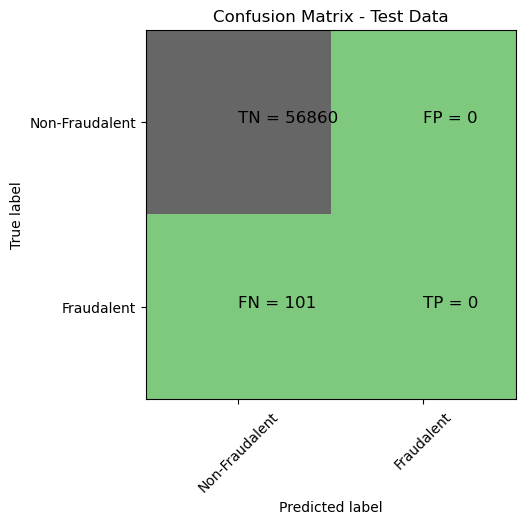

classification Report
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56860
           1       0.00      0.00      0.00       101

    accuracy                           1.00     56961
   macro avg       0.50      0.50      0.50     56961
weighted avg       1.00      1.00      1.00     56961

Accuracy pf Logistic model with l1 regularisation : 0.9990344270641316
Confusion Matrix


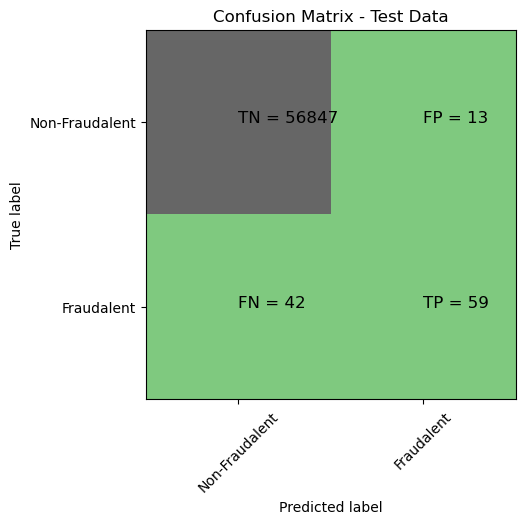

classification Report
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56860
           1       0.82      0.58      0.68       101

    accuracy                           1.00     56961
   macro avg       0.91      0.79      0.84     56961
weighted avg       1.00      1.00      1.00     56961

l2 roc_value: 0.5610479795781196
l2 threshold: 0.49919502203904054
ROC for the test dataset 56.1%


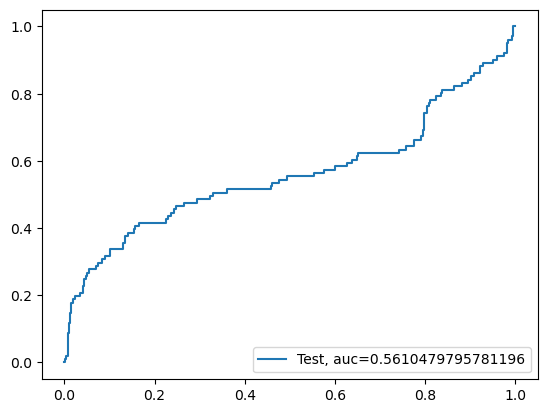

l1 roc_value: 0.8829290632193714
l1 threshold: 0.04738956200810959
ROC for the test dataset 88.3%


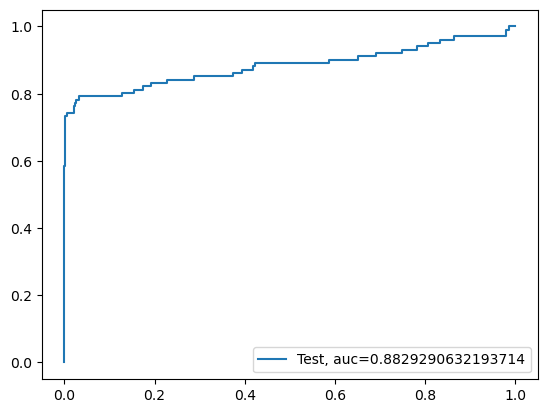

Time Taken by Model: --- 24.644329071044922 seconds ---
------------------------------------------------------------
KNN Model
model score
0.9991397622934991
Confusion Matrix


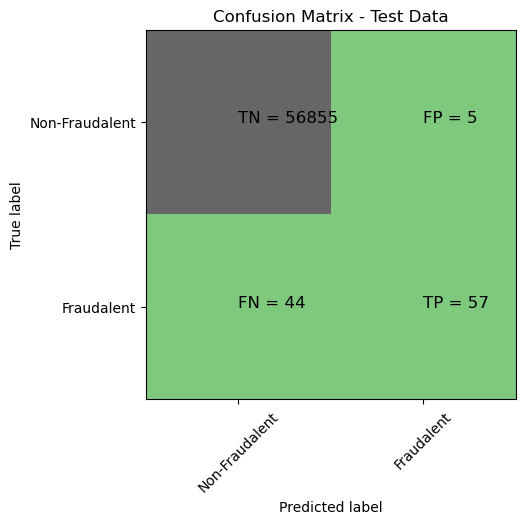

Classification Report
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56860
           1       0.92      0.56      0.70       101

    accuracy                           1.00     56961
   macro avg       0.96      0.78      0.85     56961
weighted avg       1.00      1.00      1.00     56961

KNN roc_value: 0.8710416935115952
KNN threshold: 0.2
ROC for the test dataset 87.1%


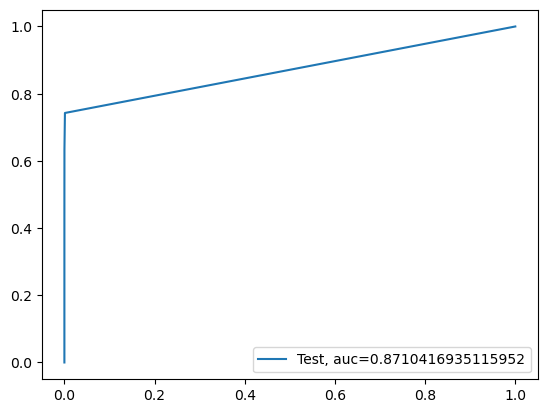

Time Taken by Model: --- 17.834352016448975 seconds ---
------------------------------------------------------------
Decision tree models with 'gini' & 'entropy' criteria
gini score: 0.9990519829356929
Confusion Matrix


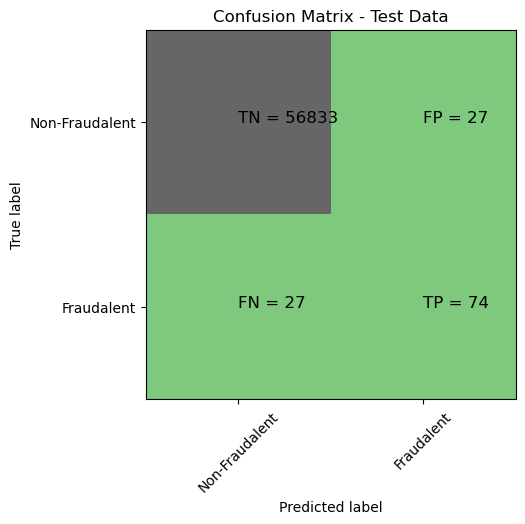

classification Report
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56860
           1       0.73      0.73      0.73       101

    accuracy                           1.00     56961
   macro avg       0.87      0.87      0.87     56961
weighted avg       1.00      1.00      1.00     56961

gini tree_roc_value: 0.8660992084083541
Tree threshold: 1.0
ROC for the test dataset 86.6%


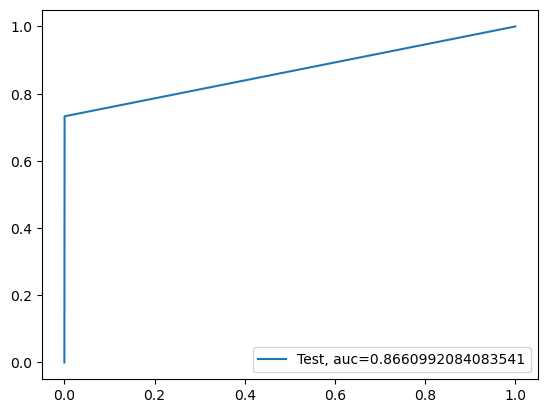

Time Taken by Model: --- 9.209103107452393 seconds ---
------------------------------------------------------------
Random Forest Model
Mocel Accuracy: 0.9995084355962852
Confusion Matrix


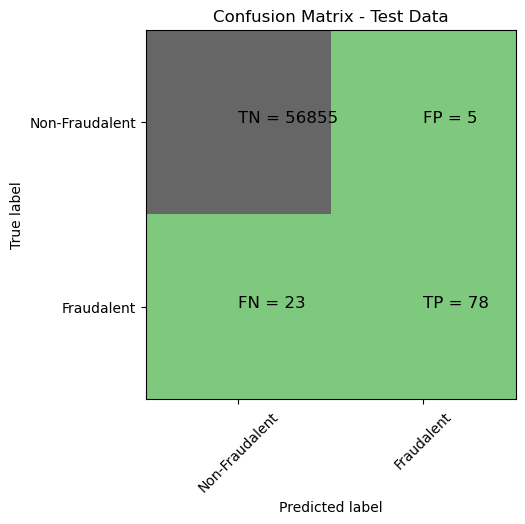

classification Report
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56860
           1       0.94      0.77      0.85       101

    accuracy                           1.00     56961
   macro avg       0.97      0.89      0.92     56961
weighted avg       1.00      1.00      1.00     56961

Random Forest roc_value: 0.9439389084881051
Random Forest threshold: 0.02
ROC for the test dataset 94.4%


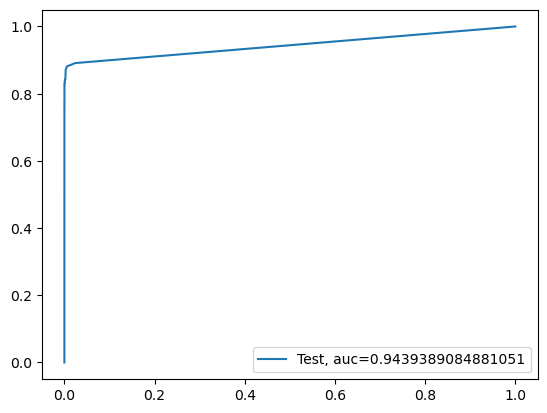

Time Taken by Model: --- 105.6892957687378 seconds ---
------------------------------------------------------------
XGBoost Model
Model Accuracy: 0.9993153210091115
Confusion Matirx


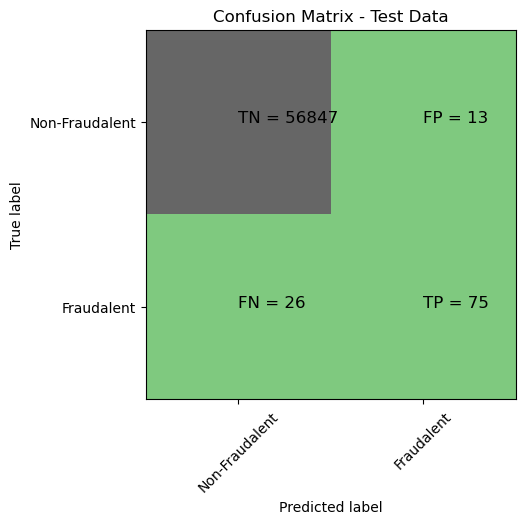

Classification Report
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56860
           1       0.85      0.74      0.79       101

    accuracy                           1.00     56961
   macro avg       0.93      0.87      0.90     56961
weighted avg       1.00      1.00      1.00     56961

XGboost roc_value: 0.9120070835785654
XGBoost threshold: 0.00017827775445766747
ROC for the test dataset 91.2%


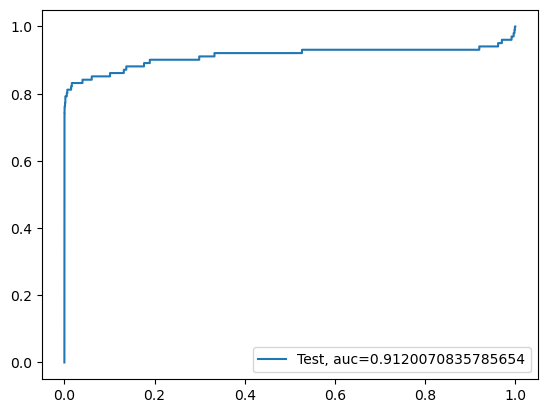

Time Taken by Model: --- 0.5109481811523438 seconds ---
------------------------------------------------------------
SVM Model with Sigmoid kernel
accuracy_score : 0.9983497480732431
Confusion Matrix


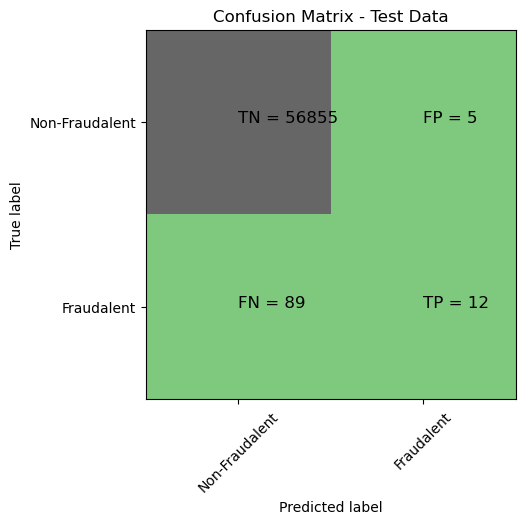

Classification Report
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56860
           1       0.71      0.12      0.20       101

    accuracy                           1.00     56961
   macro avg       0.85      0.56      0.60     56961
weighted avg       1.00      1.00      1.00     56961

SVM roc_value: 0.5058592756919026
SVM threshold: 0.001787334999894028
ROC for the test dataset: 50.6%


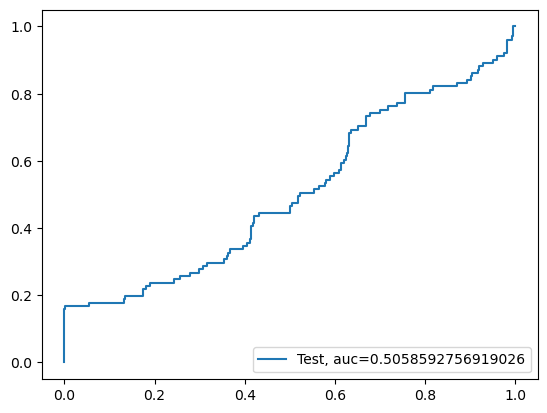

Time Taken by Model: --- 234.07854294776917 seconds ---
------------------------------------------------------------


In [33]:
#Run Logistic Regression with L1 and L2 Regularisation
print("Logistic Regression with L1 and L2 Regularisation")
start_time = time.time()
df_Results = buildAndRunLogisticModels(df_Results,"RepeatedKFold Cross Validation", X_train_cv, y_train_cv, X_test_cv, y_test_cv)
print("Time Taken by Model: --- %s seconds ---" % (time.time() - start_time))
print('-'*60)

#Run KNN Model
print("KNN Model")
start_time = time.time()
df_Results = buildAndRunKNNModels(df_Results,"RepeatedKFold Cross Validation", X_train_cv, y_train_cv, X_test_cv, y_test_cv)
print("Time Taken by Model: --- %s seconds ---" % (time.time() - start_time))
print('-'*60)

#Run Decision tree models with 'gini' & 'entropy' criteria
print("Decision tree models with 'gini' & 'entropy' criteria")
start_time = time.time()
df_Results = buildAndRunTreeModels(df_Results,"RepeatedKFold Cross Validation", X_train_cv, y_train_cv, X_test_cv, y_test_cv)
print("Time Taken by Model: --- %s seconds ---" % (time.time() - start_time))
print('-'*60)

#Run Random Forest Model
print("Random Forest Model")
start_time = time.time()
df_Results = buildAndRunRandomForestModels(df_Results,"RepeatedKFold Cross Validation", X_train_cv, y_train_cv, X_test_cv, y_test_cv)
print("Time Taken by Model: --- %s seconds ---" % (time.time() - start_time))
print('-'*60)

#Run XGBoost Model
print("XGBoost Model")
start_time = time.time()
df_Results = buildAndRunXGBoostModels(df_Results,"RepeatedKFold Cross Validation", X_train_cv, y_train_cv, X_test_cv, y_test_cv)
print("Time Taken by Model: --- %s seconds ---" % (time.time() - start_time))
print('-'*60)

#Run SVM Model with sigmoid kernel
print("SVM Model with Sigmoid kernel")
start_time = time.time()
df_Results = buildAndRunSVMModels(df_Results,"RepeatedKFold Cross Validation", X_train_cv, y_train_cv, X_test_cv, y_test_cv)
print("Time Taken by Model: --- %s seconds ---" % (time.time() - start_time))
print('-'*60)

In [34]:
# Checking the df_result dataframe which contains consolidated results of all the runs
df_Results

,Methodology,Model,Accuracy,roc_value,threshold
0,Baseline,Logistic Regression with L2 Regularisation,0.998227,0.561048,0.499195
1,Baseline,Logistic Regression with L1 Regularisation,0.998227,0.561048,0.047390
2,RepeatedKFold Cross Validation,KNN,0.999140,0.871042,0.200000
3,RepeatedKFold Cross Validation,Tree Model with gini criteria,0.999052,0.866099,1.000000
4,RepeatedKFold Cross Validation,Random Forest,0.999508,0.943939,0.020000
5,RepeatedKFold Cross Validation,XGBoost,0.999315,0.912007,0.000178
6,RepeatedKFold Cross Validation,SVM,0.998350,0.505859,0.001787


## Results for cross validation with RepeatedKFold
#### Looking at Accuracy and ROC value we have "Logistic Regression with L2 Regularisation" which has provided best results for cross validation with RepeatedKFold technique

In [58]:
# Lets perform StratifiedKFold and check the results
from sklearn.model_selection import StratifiedKFold
skf = StratifiedKFold(n_splits=5, random_state=None)
# X is the feature set and y is the target
for train_index, test_index in skf.split(X,y):
    print("TRAIN:", train_index, "TEST:", test_index)
    X_train_SKF_cv, X_test_SKF_cv = X.iloc[train_index], X.iloc[test_index]
    y_train_SKF_cv, y_test_SKF_cv = y.iloc[train_index], y.iloc[test_index] 

TRAIN: [ 30473  30496  31002 ... 284804 284805 284806] TEST: [    0     1     2 ... 57017 57018 57019]
TRAIN: [     0      1      2 ... 284804 284805 284806] TEST: [ 30473  30496  31002 ... 113964 113965 113966]
TRAIN: [     0      1      2 ... 284804 284805 284806] TEST: [ 81609  82400  83053 ... 170946 170947 170948]
TRAIN: [     0      1      2 ... 284804 284805 284806] TEST: [150654 150660 150661 ... 227866 227867 227868]
TRAIN: [     0      1      2 ... 227866 227867 227868] TEST: [212516 212644 213092 ... 284804 284805 284806]


Logistic Regression with L1 and L2 Regularisation
Max auc_roc for l1: 0.9652106893977332
Max auc_roc for l2: 0.5597020083683936
Parameters for l1 regularisations
[[-0.03660539 -0.1358827  -0.20474594  0.04333662 -0.24034598  0.08416903
   0.12654905 -0.04815306 -0.14258132 -0.1384162  -0.11668372  0.05505155
  -0.15637116 -0.24216184 -0.03137093 -0.09904364 -0.23133976  0.05582481
   0.02122044  0.20503748  0.09013502  0.00148754 -0.03796378 -0.00392139
  -0.14797782 -0.00701001 -0.06594801 -0.00660368 -0.00656465 -0.12981985]]
[-2.0409044]
{np.int64(1): array([[0.5       , 0.5       , 0.5       , 0.5       , 0.48341269,
        0.44979055, 0.48500892, 0.78098262, 0.9497821 , 0.94525947,
        0.91827811, 0.91446679, 0.94989144, 0.94933682, 0.94178407,
        0.94900653, 0.92481293, 0.94421561, 0.9164553 , 0.97793244],
       [0.5       , 0.5       , 0.5       , 0.5       , 0.54612019,
        0.57709187, 0.60597219, 0.84651057, 0.93343227, 0.93465714,
        0.92629828, 0.92557122

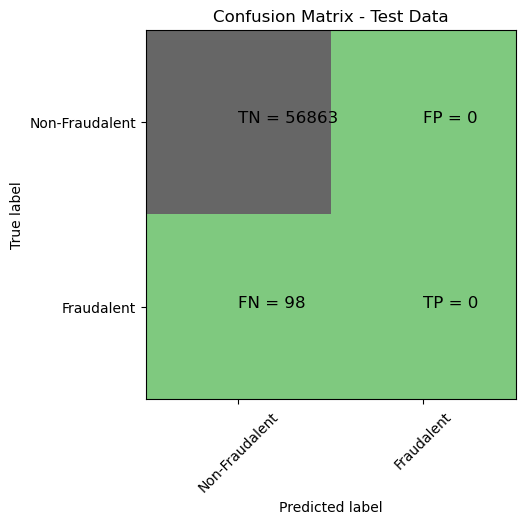

classification Report
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56863
           1       0.00      0.00      0.00        98

    accuracy                           1.00     56961
   macro avg       0.50      0.50      0.50     56961
weighted avg       1.00      1.00      1.00     56961

Accuracy pf Logistic model with l1 regularisation : 0.9987535331191517
Confusion Matrix


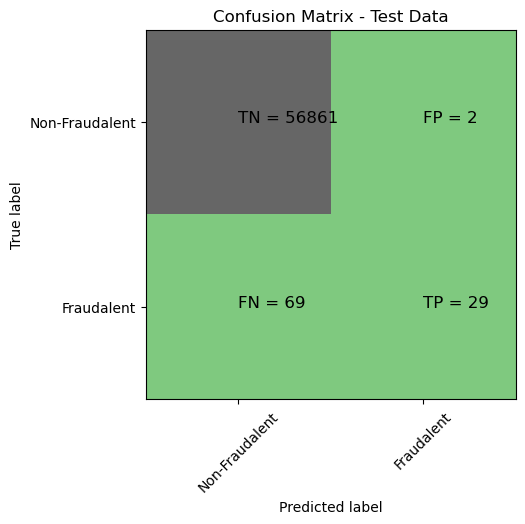

classification Report
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56863
           1       0.94      0.30      0.45        98

    accuracy                           1.00     56961
   macro avg       0.97      0.65      0.72     56961
weighted avg       1.00      1.00      1.00     56961

l2 roc_value: 0.6111619154810686
l2 threshold: 0.4993921957728672
ROC for the test dataset 61.1%


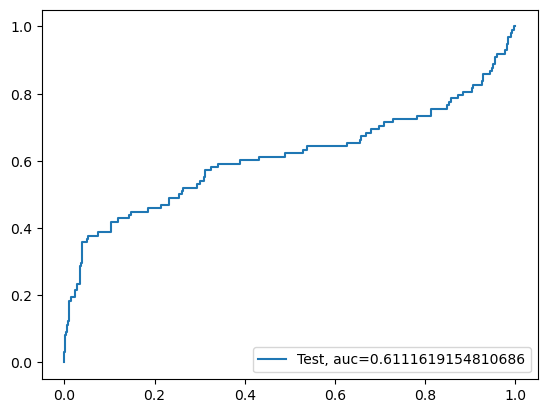

l1 roc_value: 0.8890758561483437
l1 threshold: 0.021087492766199784
ROC for the test dataset 88.9%


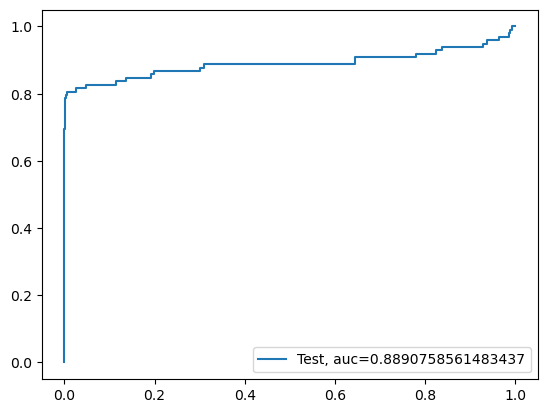

Time Taken by Model: --- 25.068557024002075 seconds ---
------------------------------------------------------------
KNN Model
model score
0.9991924299081828
Confusion Matrix


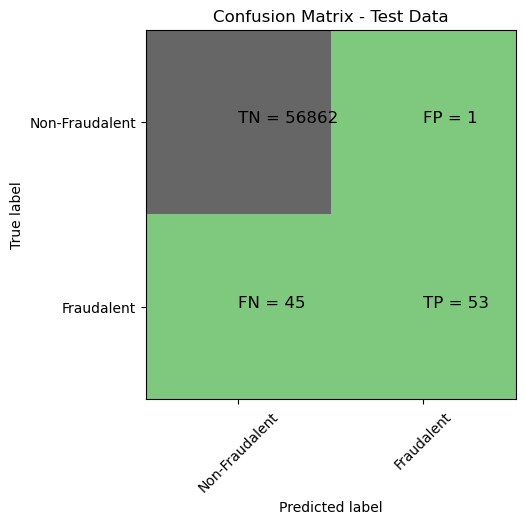

Classification Report
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56863
           1       0.98      0.54      0.70        98

    accuracy                           1.00     56961
   macro avg       0.99      0.77      0.85     56961
weighted avg       1.00      1.00      1.00     56961

KNN roc_value: 0.8057457828285457
KNN threshold: 0.2
ROC for the test dataset 80.6%


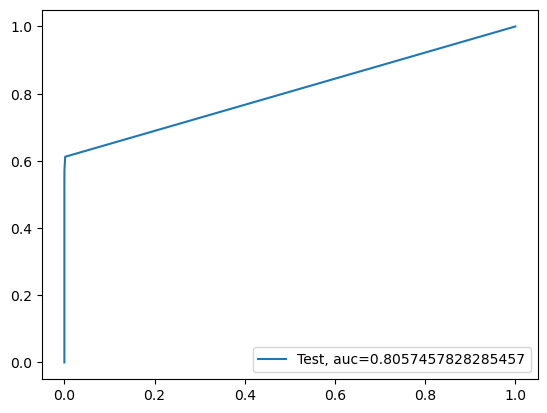

Time Taken by Model: --- 17.678873777389526 seconds ---
------------------------------------------------------------
Decision tree models with 'gini' & 'entropy' criteria
gini score: 0.998841312476958
Confusion Matrix


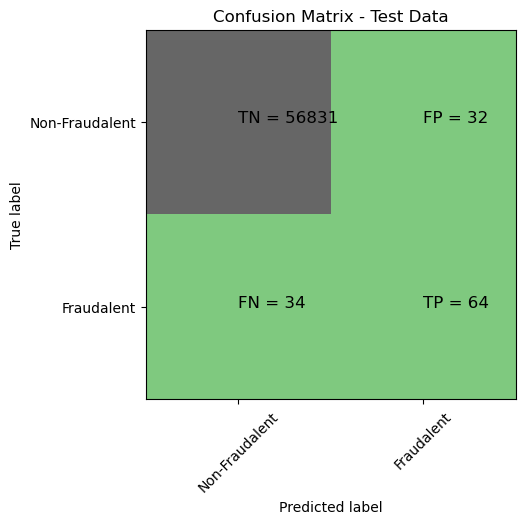

classification Report
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56863
           1       0.67      0.65      0.66        98

    accuracy                           1.00     56961
   macro avg       0.83      0.83      0.83     56961
weighted avg       1.00      1.00      1.00     56961

gini tree_roc_value: 0.8262492341959029
Tree threshold: 1.0
ROC for the test dataset 82.6%


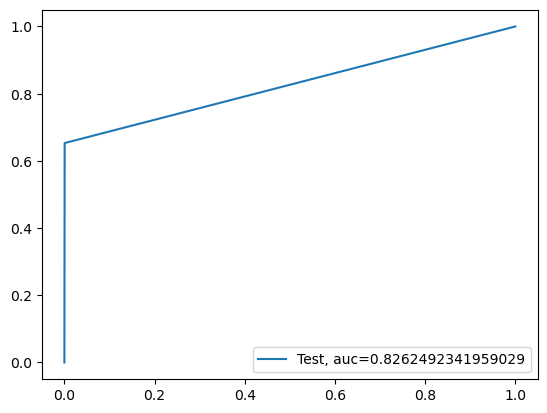

Time Taken by Model: --- 10.421406984329224 seconds ---
------------------------------------------------------------
Random Forest Model
Mocel Accuracy: 0.9994382121100402
Confusion Matrix


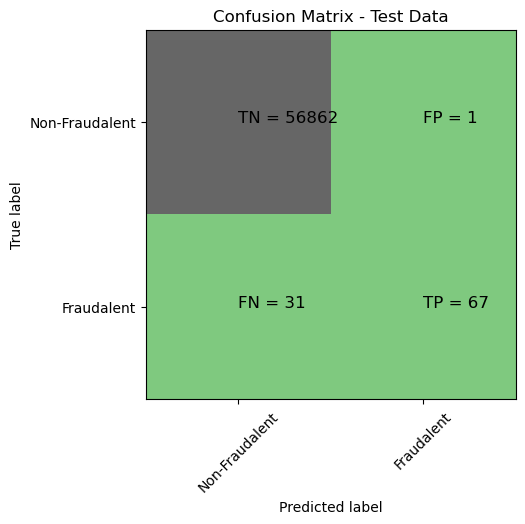

classification Report
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56863
           1       0.99      0.68      0.81        98

    accuracy                           1.00     56961
   macro avg       0.99      0.84      0.90     56961
weighted avg       1.00      1.00      1.00     56961

Random Forest roc_value: 0.9464721329855826
Random Forest threshold: 0.01
ROC for the test dataset 94.6%


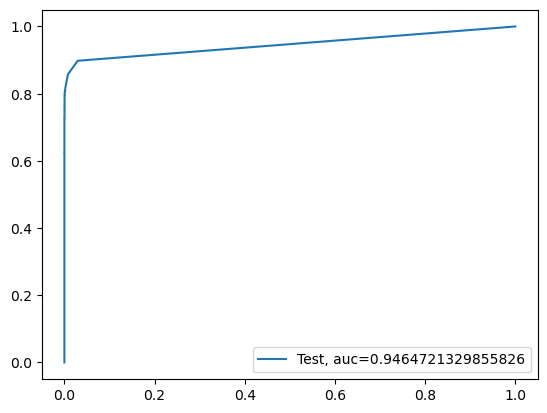

Time Taken by Model: --- 98.60004615783691 seconds ---
------------------------------------------------------------
XGBoost Model
Model Accuracy: 0.9991748740366215
Confusion Matirx


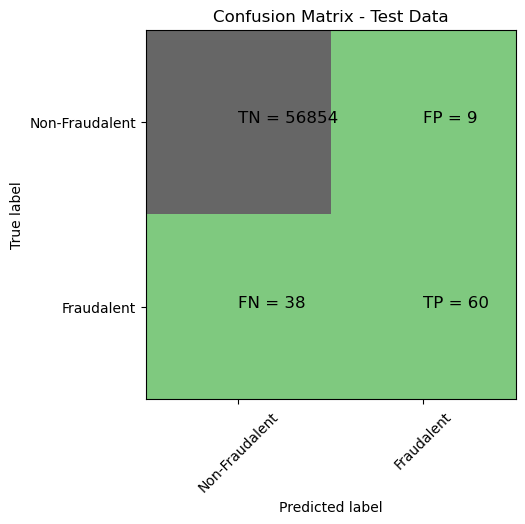

Classification Report
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56863
           1       0.87      0.61      0.72        98

    accuracy                           1.00     56961
   macro avg       0.93      0.81      0.86     56961
weighted avg       1.00      1.00      1.00     56961

XGboost roc_value: 0.8722069011555522
XGBoost threshold: 0.00012704679102171212
ROC for the test dataset 87.2%


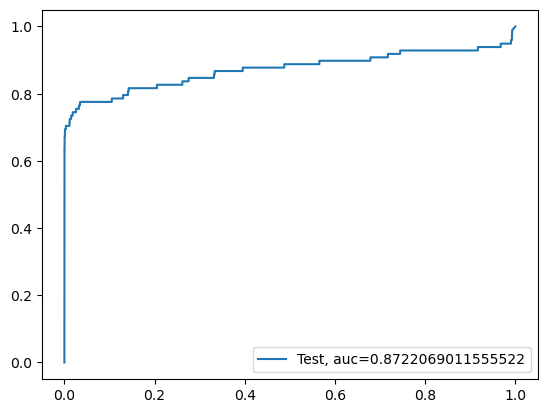

Time Taken by Model: --- 0.5152370929718018 seconds ---
------------------------------------------------------------
SVM Model with Sigmoid kernel
accuracy_score : 0.9982795245869981
Confusion Matrix


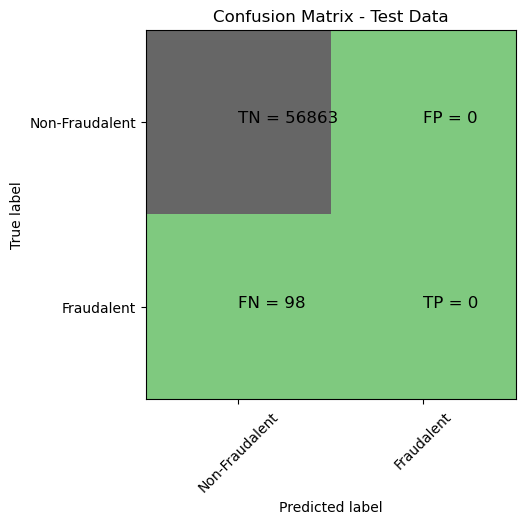

Classification Report
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56863
           1       0.00      0.00      0.00        98

    accuracy                           1.00     56961
   macro avg       0.50      0.50      0.50     56961
weighted avg       1.00      1.00      1.00     56961

SVM roc_value: 0.40177034885494567
SVM threshold: 0.004327533702747318
ROC for the test dataset: 40.2%


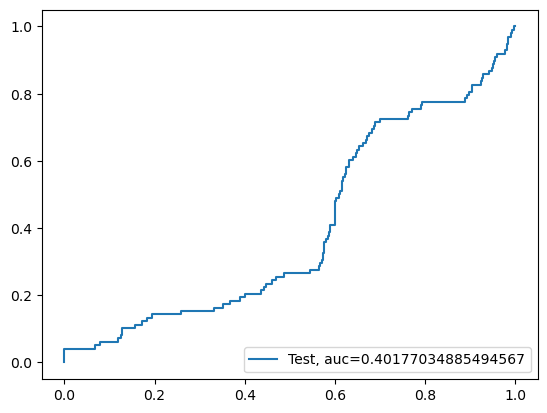

Time Taken by Model: --- 52.88215494155884 seconds ---
------------------------------------------------------------


In [36]:
#Run Logistic Regression with L1 and L2 Regularisation
print("Logistic Regression with L1 and L2 Regularisation")
start_time = time.time()
df_Results = buildAndRunLogisticModels(df_Results,"StratifiedKFold Cross Validation", X_train_SKF_cv, y_train_SKF_cv, X_test_SKF_cv, y_test_SKF_cv)
print("Time Taken by Model: --- %s seconds ---" % (time.time() - start_time))
print('-'*60)

#Run KNN Model
print("KNN Model")
start_time = time.time()
df_Results = buildAndRunKNNModels(df_Results,"StratifiedKFold Cross Validation", X_train_SKF_cv, y_train_SKF_cv, X_test_SKF_cv, y_test_SKF_cv)
print("Time Taken by Model: --- %s seconds ---" % (time.time() - start_time))
print('-'*60)

#Run Decision tree models with 'gini' & 'entropy' criteria
print("Decision tree models with 'gini' & 'entropy' criteria")
start_time = time.time()
df_Results = buildAndRunTreeModels(df_Results,"StratifiedKFold Cross Validation", X_train_SKF_cv, y_train_SKF_cv, X_test_SKF_cv, y_test_SKF_cv)
print("Time Taken by Model: --- %s seconds ---" % (time.time() - start_time))
print('-'*60)

#Run Random Forest Model
print("Random Forest Model")
start_time = time.time()
df_Results = buildAndRunRandomForestModels(df_Results,"StratifiedKFold Cross Validation", X_train_SKF_cv, y_train_SKF_cv, X_test_SKF_cv, y_test_SKF_cv)
print("Time Taken by Model: --- %s seconds ---" % (time.time() - start_time))
print('-'*60)

#Run XGBoost Model
print("XGBoost Model")
start_time = time.time()
df_Results = buildAndRunXGBoostModels(df_Results,"StratifiedKFold Cross Validation", X_train_SKF_cv, y_train_SKF_cv, X_test_SKF_cv, y_test_SKF_cv)
print("Time Taken by Model: --- %s seconds ---" % (time.time() - start_time))
print('-'*60)

#Run SVM Model with sigmoid kernel
print("SVM Model with Sigmoid kernel")
start_time = time.time()
df_Results = buildAndRunSVMModels(df_Results,"StratifiedKFold Cross Validation", X_train_SKF_cv, y_train_SKF_cv, X_test_SKF_cv, y_test_SKF_cv)
print("Time Taken by Model: --- %s seconds ---" % (time.time() - start_time))
print('-'*60)

In [37]:
# Checking the df_result dataframe which contains consolidated results of all the runs
df_Results

,Methodology,Model,Accuracy,roc_value,threshold
0,Baseline,Logistic Regression with L2 Regularisation,0.998227,0.561048,0.499195
1,Baseline,Logistic Regression with L1 Regularisation,0.998227,0.561048,0.047390
2,RepeatedKFold Cross Validation,KNN,0.999140,0.871042,0.200000
3,RepeatedKFold Cross Validation,Tree Model with gini criteria,0.999052,0.866099,1.000000
4,RepeatedKFold Cross Validation,Random Forest,0.999508,0.943939,0.020000
5,RepeatedKFold Cross Validation,XGBoost,0.999315,0.912007,0.000178
6,RepeatedKFold Cross Validation,SVM,0.998350,0.505859,0.001787
7,Baseline,Logistic Regression with L2 Regularisation,0.998280,0.611162,0.499392
8,Baseline,Logistic Regression with L1 Regularisation,0.998280,0.611162,0.021087
9,StratifiedKFold Cross Validation,KNN,0.999192,0.805746,0.200000


## Results for cross validation with StratifiedKFold
#### Looking at Accuracy and ROC value we have "XGBoost" which has provided best results for cross validation with RepeatedKFold technique

# Conclusion:
## As the results show Random Forest at RepeatedKFold Cross validation provided best results

In [38]:
#Logistic Regression
from sklearn import linear_model
from sklearn.model_selection import KFold

num_C = list(np.power(10.0, np.arange(-10, 10)))
cv_num = KFold(n_splits=10, shuffle=True, random_state=42)

clf = linear_model.LogisticRegressionCV(
        Cs= num_C
        ,penalty ='l2'
        ,scoring='roc_auc'
        ,cv=cv_num
        ,random_state=42
        ,max_iter=10000
        ,fit_intercept=True
        ,solver='newton-cg'
        ,tol=10
    )

clf.fit(X_train_SKF_cv, y_train_SKF_cv)
print('Max auc_roc for l2:', clf.scores_[1].mean(axis=0).max())

print("Parameters for l2 regularisations")
print(clf.coef_)
print(clf.intercept_)
print(clf.scores_)

#find predicted values
y_pred_l2 = clf.predict(X_test)

#Find predicted probabilites
y_pred_probs_l2 = clf.predict_proba(X_test)[:,1]

# Accuracy of L2/L1 models
Accuracy_l2 = metrics.accuracy_score(y_pred = y_pred_l2, y_true = y_test)

print("Accuracy of Logistic model with l2 regularisation: {0}".format(Accuracy_l2))

from sklearn.metrics import roc_auc_score
l2_roc_value = roc_auc_score(y_test, y_pred_probs_l2)
print("l2 roc_value: {0}".format(l2_roc_value))
fpr, tpr, thresholds = metrics.roc_curve(y_test, y_pred_probs_l2)
threshold = thresholds[np.argmax(tpr-fpr)]
print("l2 threshold: {0}".format(threshold))


Max auc_roc for l2: 0.5597020083683936
Parameters for l2 regularisations
[[ 3.59840980e-07  2.10530060e-07 -1.58002317e-06 -2.04884044e-07
   3.76472678e-07 -2.67633109e-07  3.13241030e-08 -1.20226136e-08
  -8.98863463e-08 -1.54002314e-07 -4.65334035e-07  1.57441535e-07
  -1.27094538e-07 -4.38050832e-07 -3.73274685e-07 -8.23337714e-08
  -3.16607926e-07  1.01807717e-07  7.54814354e-08 -6.47175864e-08
   7.04219521e-08  1.73013268e-07  7.32726162e-08 -1.03599764e-08
  -2.85545640e-07 -2.03747293e-08  3.38203553e-09 -1.32510707e-08
  -6.82254904e-04 -9.57433590e-05]]
[-7.52178855e-06]
{np.int64(1): array([[0.48266925, 0.48178322, 0.47951852, 0.47631818, 0.47631818,
        0.47631818, 0.47631818, 0.47631818, 0.47631818, 0.47631818,
        0.47631818, 0.47631818, 0.47631818, 0.47631818, 0.47631818,
        0.47631818, 0.47631818, 0.47631818, 0.47631818, 0.47631818],
       [0.55602862, 0.55598183, 0.55533056, 0.55524448, 0.55524448,
        0.55524448, 0.55524448, 0.55524448, 0.55524448, 

In [39]:
#Checking the coefficient values
clf.coef_

array([[ 3.59840980e-07,  2.10530060e-07, -1.58002317e-06,
        -2.04884044e-07,  3.76472678e-07, -2.67633109e-07,
         3.13241030e-08, -1.20226136e-08, -8.98863463e-08,
        -1.54002314e-07, -4.65334035e-07,  1.57441535e-07,
        -1.27094538e-07, -4.38050832e-07, -3.73274685e-07,
        -8.23337714e-08, -3.16607926e-07,  1.01807717e-07,
         7.54814354e-08, -6.47175864e-08,  7.04219521e-08,
         1.73013268e-07,  7.32726162e-08, -1.03599764e-08,
        -2.85545640e-07, -2.03747293e-08,  3.38203553e-09,
        -1.32510707e-08, -6.82254904e-04, -9.57433590e-05]])

In [40]:
# Creating a dataframe with the coefficient values
coefficients = pd.concat([pd.DataFrame(X.columns), pd.DataFrame(np.transpose(clf.coef_))], axis = 1)
coefficients.columns = ['Feature', 'Importance Coefficient']

In [41]:
coefficients

,Feature,Importance Coefficient
0,V1,3.598410e-07
1,V2,2.105301e-07
2,V3,-1.580023e-06
3,V4,-2.048840e-07
4,V5,3.764727e-07
5,V6,-2.676331e-07
6,V7,3.132410e-08
7,V8,-1.202261e-08
8,V9,-8.988635e-08
9,V10,-1.540023e-07


# Print the important features of the best model to understand the dataset
## This will not give much explanation on the already transformed dataset
## But it will help us understanding if the dataset is not PCA transformed

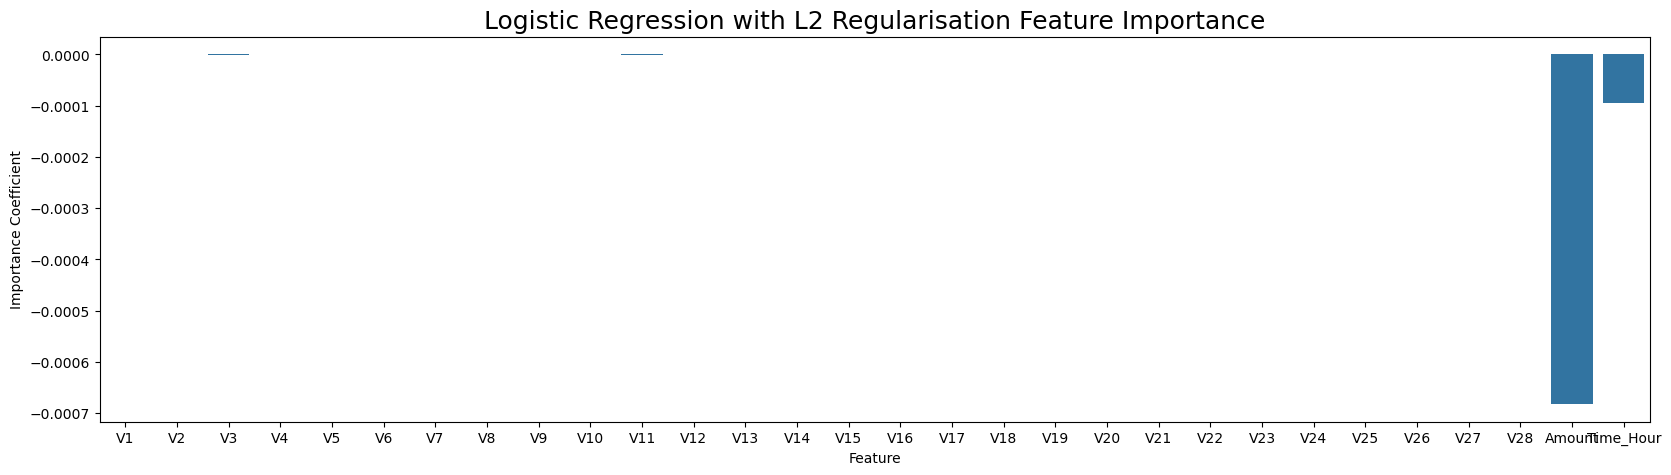

In [42]:
#Plotting the Coefficient values
plt.figure(figsize=(20,5))
sns.barplot(x='Feature', y='Importance Coefficient', data = coefficients)
plt.title("Logistic Regression with L2 Regularisation Feature Importance", fontsize=18)

plt.show()

## The above image shows the Logistic Regression with L2 Regularisation Feature Importance

# Model building with balancing class

## Perform class balancing with:
#### Random Oversampling
#### SMOTE
#### ADASYN

# Oversampling with RandomOverSampler with StratifiedKFold Cross Validation
## We will use Random, Oversampling method to handle the class imbalance

In [43]:
# creating the dataset with RandomOverSampler and StratifiedKFold
from sklearn.model_selection import StratifiedKFold
from imblearn.over_sampling import RandomOverSampler

skf = StratifiedKFold(n_splits=5, random_state=None)

for fold, (train_index, test_index) in enumerate(skf.split(X,y), 1):
    X_train = X.loc[train_index]
    y_train = y.loc[train_index]
    X_test = X.loc[test_index]
    y_test = y.loc[test_index]
    ROS = RandomOverSampler(sampling_strategy=0.5)
    X_over, y_over = ROS.fit_resample(X_train, y_train)

X_over = pd.DataFrame(data=X_over, columns=cols)  

Logistic Regression with L1 and L2 Regularisation
Max auc_roc for l1: 0.5
Max auc_roc for l2: 0.5
Parameters for l1 regularisations
[[0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
  0. 0. 0. 0. 0. 0.]]
[0.]
{np.int64(1): array([[0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5,
        0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5],
       [0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5,
        0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5],
       [0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5,
        0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5],
       [0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5,
        0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5],
       [0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5,
        0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5],
       [0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5,
        0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5],
       [0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5

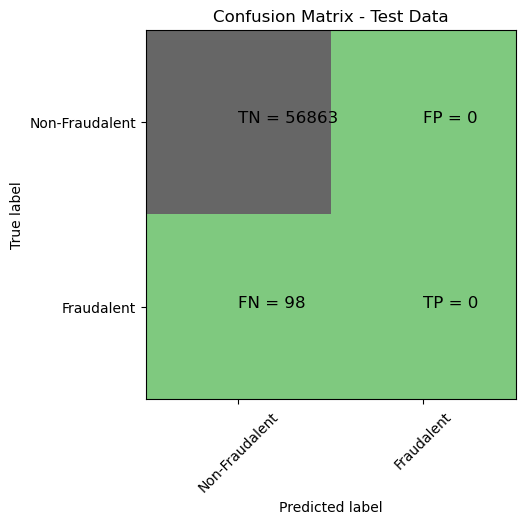

classification Report
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56863
           1       0.00      0.00      0.00        98

    accuracy                           1.00     56961
   macro avg       0.50      0.50      0.50     56961
weighted avg       1.00      1.00      1.00     56961

Accuracy pf Logistic model with l1 regularisation : 0.9982795245869981
Confusion Matrix


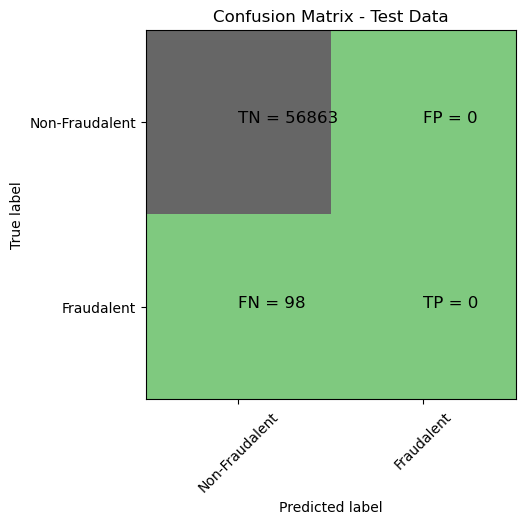

classification Report
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56863
           1       0.00      0.00      0.00        98

    accuracy                           1.00     56961
   macro avg       0.50      0.50      0.50     56961
weighted avg       1.00      1.00      1.00     56961

l2 roc_value: 0.5
l2 threshold: inf
ROC for the test dataset 50.0%


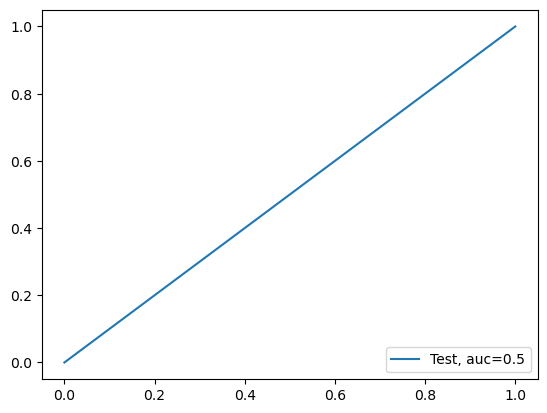

l1 roc_value: 0.5
l1 threshold: inf
ROC for the test dataset 50.0%


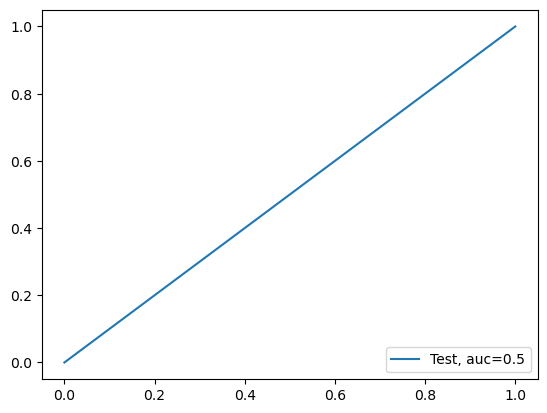

Time Taken by Model: --- 20.237644910812378 seconds ---
------------------------------------------------------------
KNN Model
model score
0.9980688541282632
Confusion Matrix


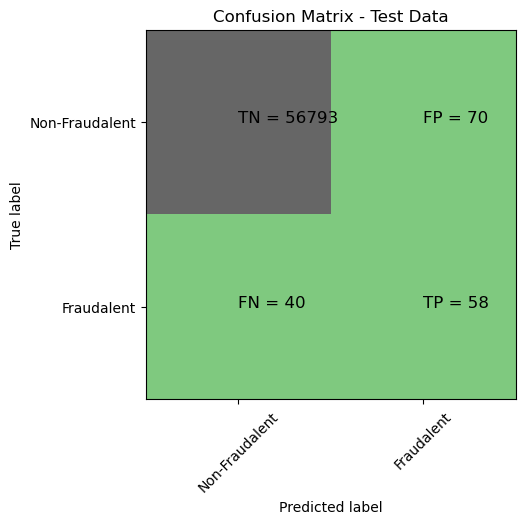

Classification Report
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56863
           1       0.45      0.59      0.51        98

    accuracy                           1.00     56961
   macro avg       0.73      0.80      0.76     56961
weighted avg       1.00      1.00      1.00     56961

KNN roc_value: 0.805604465728046
KNN threshold: 0.2
ROC for the test dataset 80.6%


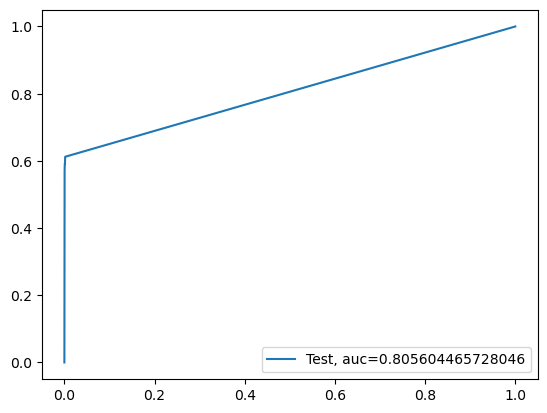

Time Taken by Model: --- 25.675698280334473 seconds ---
------------------------------------------------------------
Decision tree models with 'gini' & 'entropy' criteria
gini score: 0.9987535331191517
Confusion Matrix


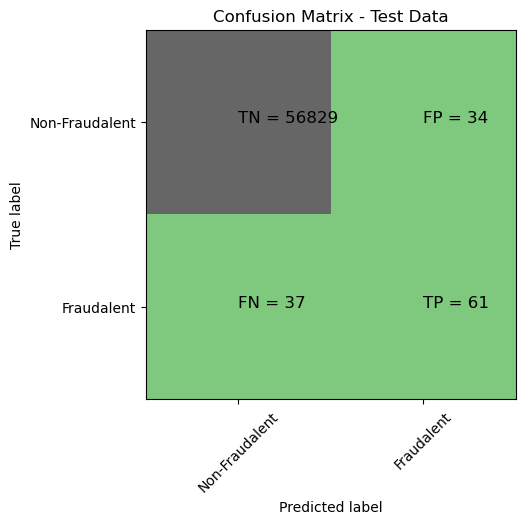

classification Report
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56863
           1       0.64      0.62      0.63        98

    accuracy                           1.00     56961
   macro avg       0.82      0.81      0.82     56961
weighted avg       1.00      1.00      1.00     56961

gini tree_roc_value: 0.8109255256188612
Tree threshold: 1.0
ROC for the test dataset 81.1%


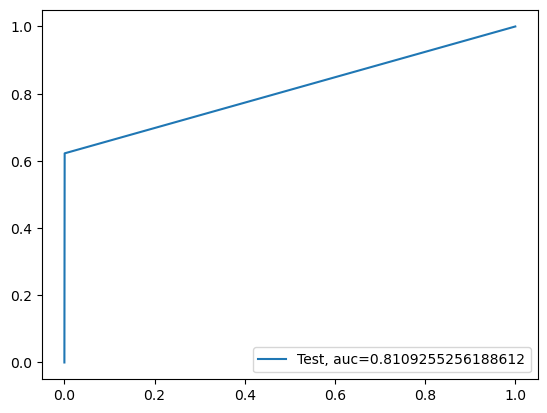

Time Taken by Model: --- 5.87791109085083 seconds ---
------------------------------------------------------------
Random Forest Model
Mocel Accuracy: 0.9995084355962852
Confusion Matrix


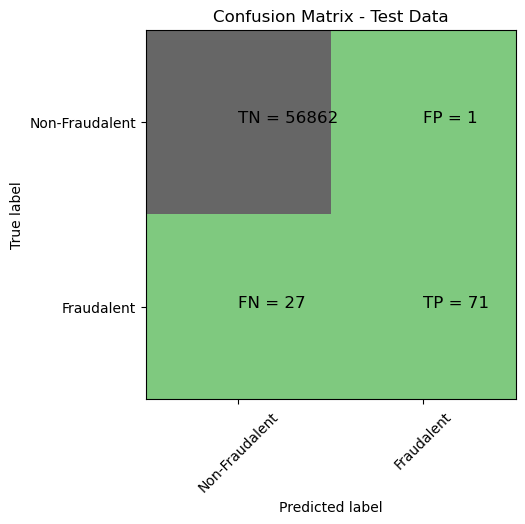

classification Report
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56863
           1       0.99      0.72      0.84        98

    accuracy                           1.00     56961
   macro avg       0.99      0.86      0.92     56961
weighted avg       1.00      1.00      1.00     56961

Random Forest roc_value: 0.9309856629988225
Random Forest threshold: 0.02
ROC for the test dataset 93.1%


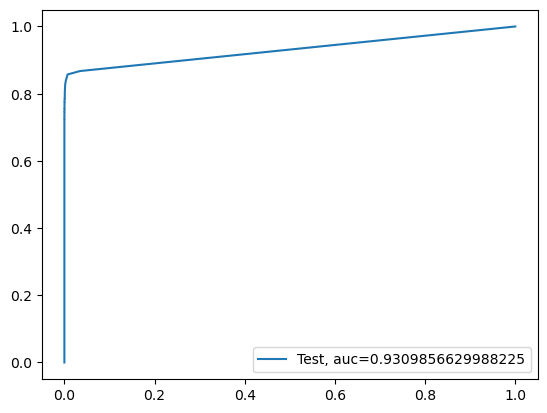

Time Taken by Model: --- 74.63410925865173 seconds ---
------------------------------------------------------------
XGBoost Model
Model Accuracy: 0.9994557679816014
Confusion Matirx


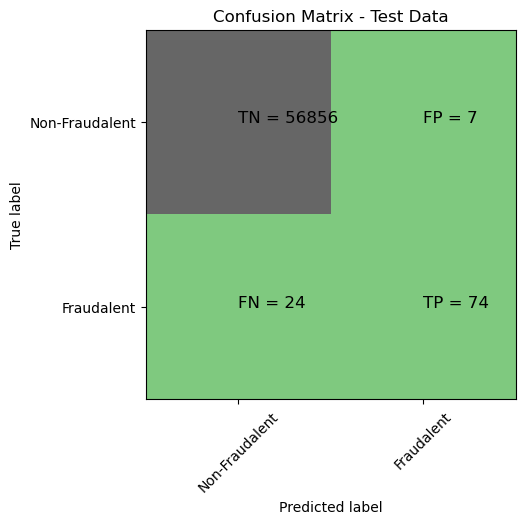

Classification Report
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56863
           1       0.91      0.76      0.83        98

    accuracy                           1.00     56961
   macro avg       0.96      0.88      0.91     56961
weighted avg       1.00      1.00      1.00     56961

XGboost roc_value: 0.982182650243855
XGBoost threshold: 8.240847091656178e-05
ROC for the test dataset 98.2%


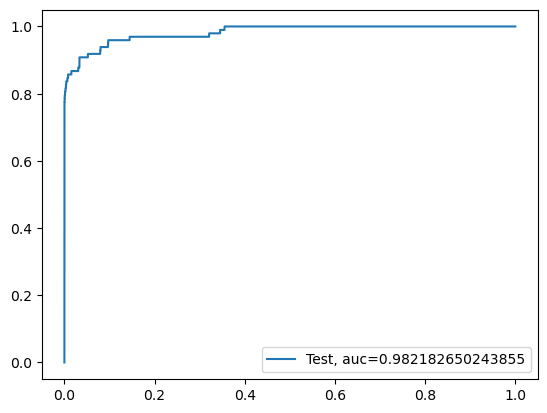

Time Taken by Model: --- 0.672278881072998 seconds ---
------------------------------------------------------------


In [44]:
Data_Imbalance_Handiling = "Random Oversampling with StratifiedKFold CV"
#Run Logistic Regression with L1 and L2 Regularisation
print("Logistic Regression with L1 and L2 Regularisation")
start_time = time.time()
df_Results = buildAndRunLogisticModels(df_Results, Data_Imbalance_Handiling, X_over, y_over, X_test, y_test)
print("Time Taken by Model: --- %s seconds ---" % (time.time() - start_time))
print('-'*60)

#Run KNN Model
print("KNN Model")
start_time = time.time()
df_Results = buildAndRunKNNModels(df_Results, Data_Imbalance_Handiling, X_over, y_over, X_test, y_test)
print("Time Taken by Model: --- %s seconds ---" % (time.time() - start_time))
print('-'*60)

#Run Decision tree models with 'gini' & 'entropy' criteria
print("Decision tree models with 'gini' & 'entropy' criteria")
start_time = time.time()
df_Results = buildAndRunTreeModels(df_Results, Data_Imbalance_Handiling, X_over, y_over, X_test, y_test)
print("Time Taken by Model: --- %s seconds ---" % (time.time() - start_time))
print('-'*60)

#Run Random Forest Model
print("Random Forest Model")
start_time = time.time()
df_Results = buildAndRunRandomForestModels(df_Results, Data_Imbalance_Handiling, X_over, y_over, X_test, y_test)
print("Time Taken by Model: --- %s seconds ---" % (time.time() - start_time))
print('-'*60)

#Run XGBoost Model
print("XGBoost Model")
start_time = time.time()
df_Results = buildAndRunXGBoostModels(df_Results, Data_Imbalance_Handiling, X_over, y_over, X_test, y_test)
print("Time Taken by Model: --- %s seconds ---" % (time.time() - start_time))
print('-'*60)

In [45]:
# Checking the df_result dataframe which contains consolidated results of all the runs
df_Results

,Methodology,Model,Accuracy,roc_value,threshold
0,Baseline,Logistic Regression with L2 Regularisation,0.998227,0.561048,0.499195
1,Baseline,Logistic Regression with L1 Regularisation,0.998227,0.561048,0.047390
2,RepeatedKFold Cross Validation,KNN,0.999140,0.871042,0.200000
3,RepeatedKFold Cross Validation,Tree Model with gini criteria,0.999052,0.866099,1.000000
4,RepeatedKFold Cross Validation,Random Forest,0.999508,0.943939,0.020000
5,RepeatedKFold Cross Validation,XGBoost,0.999315,0.912007,0.000178
6,RepeatedKFold Cross Validation,SVM,0.998350,0.505859,0.001787
7,Baseline,Logistic Regression with L2 Regularisation,0.998280,0.611162,0.499392
8,Baseline,Logistic Regression with L1 Regularisation,0.998280,0.611162,0.021087
9,StratifiedKFold Cross Validation,KNN,0.999192,0.805746,0.200000


# Oversampling with SMOTE Oversampling
### We will use SMOTE Oversampling method to handle the class imbalance

In [46]:
# creating the dataset with RandomOverSampler and StratifiedKFold
from sklearn.model_selection import StratifiedKFold
from imblearn import over_sampling

skf = StratifiedKFold(n_splits=5, random_state=None)

for fold, (train_index, test_index) in enumerate(skf.split(X,y), 1):
    X_train = X.loc[train_index]
    y_train = y.loc[train_index]
    X_test = X.loc[test_index]
    y_test = y.loc[test_index]
    SMOTE = over_sampling.SMOTE(random_state=0)
    X_train_Smote, y_train_Smote = SMOTE.fit_resample(X_train, y_train)

X_train_Smote = pd.DataFrame(data=X_train_Smote, columns=cols)  

Logistic Regression with L1 and L2 Regularisation
Max auc_roc for l1: 0.5
Max auc_roc for l2: 0.5
Parameters for l1 regularisations
[[0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
  0. 0. 0. 0. 0. 0.]]
[0.]
{np.int64(1): array([[0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5,
        0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5],
       [0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5,
        0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5],
       [0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5,
        0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5],
       [0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5,
        0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5],
       [0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5,
        0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5],
       [0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5,
        0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5],
       [0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5

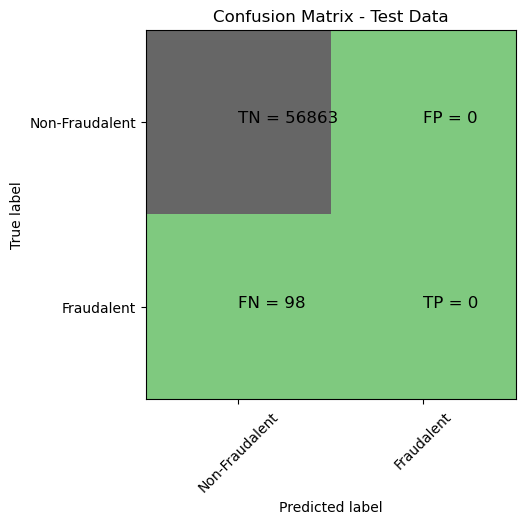

classification Report
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56863
           1       0.00      0.00      0.00        98

    accuracy                           1.00     56961
   macro avg       0.50      0.50      0.50     56961
weighted avg       1.00      1.00      1.00     56961

Accuracy pf Logistic model with l1 regularisation : 0.9982795245869981
Confusion Matrix


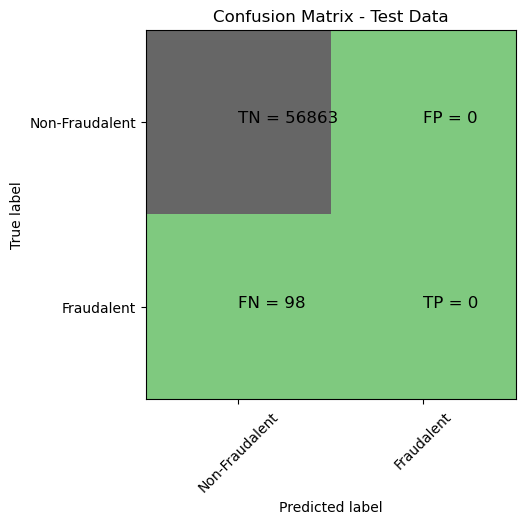

classification Report
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56863
           1       0.00      0.00      0.00        98

    accuracy                           1.00     56961
   macro avg       0.50      0.50      0.50     56961
weighted avg       1.00      1.00      1.00     56961

l2 roc_value: 0.5
l2 threshold: inf
ROC for the test dataset 50.0%


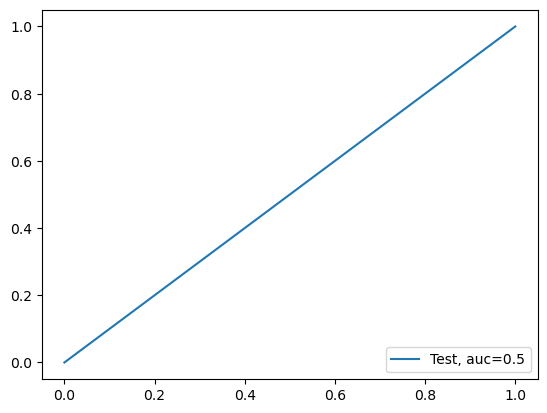

l1 roc_value: 0.5
l1 threshold: inf
ROC for the test dataset 50.0%


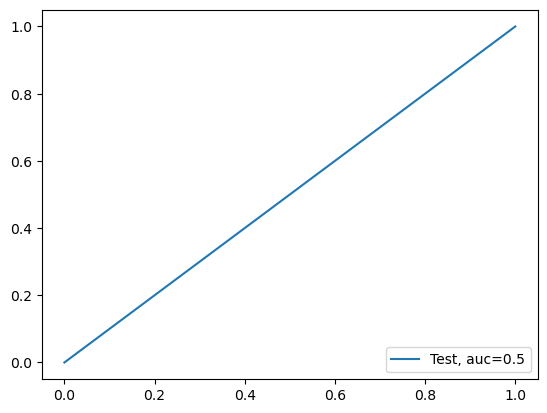

Time Taken by Model: --- 26.48580312728882 seconds ---
------------------------------------------------------------
KNN Model
model score
0.9946805709169432
Confusion Matrix


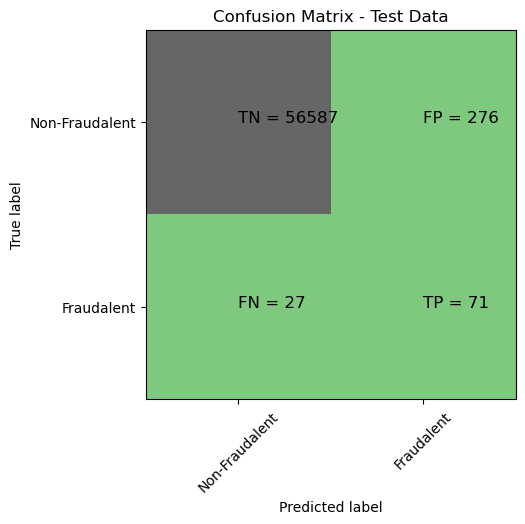

Classification Report
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56863
           1       0.20      0.72      0.32        98

    accuracy                           0.99     56961
   macro avg       0.60      0.86      0.66     56961
weighted avg       1.00      0.99      1.00     56961

KNN roc_value: 0.8602674455287628
KNN threshold: 0.6
ROC for the test dataset 86.0%


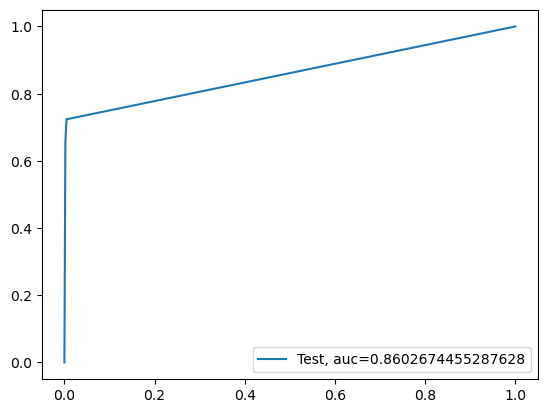

Time Taken by Model: --- 38.11886191368103 seconds ---
------------------------------------------------------------
Decision tree models with 'gini' & 'entropy' criteria
gini score: 0.9977001808254771
Confusion Matrix


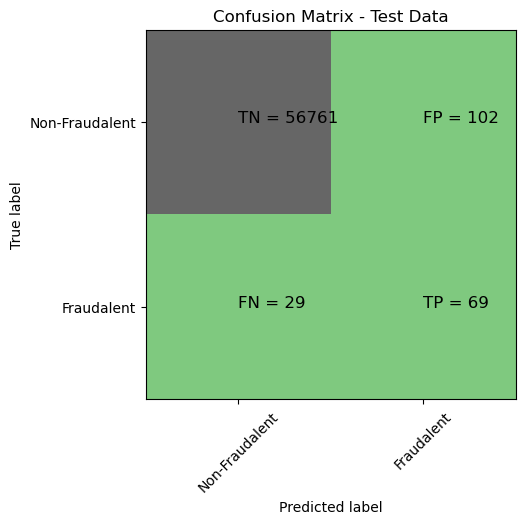

classification Report
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56863
           1       0.40      0.70      0.51        98

    accuracy                           1.00     56961
   macro avg       0.70      0.85      0.76     56961
weighted avg       1.00      1.00      1.00     56961

gini tree_roc_value: 0.8511439237953592
Tree threshold: 1.0
ROC for the test dataset 85.1%


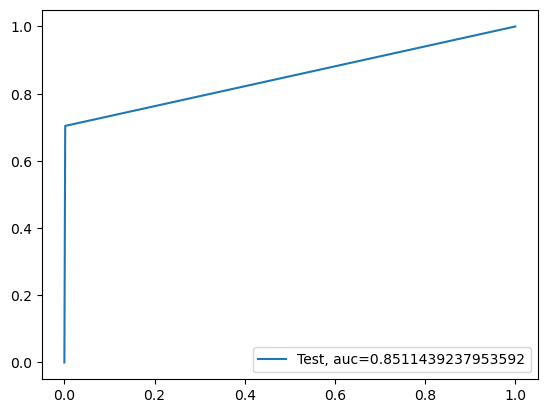

Time Taken by Model: --- 23.551182746887207 seconds ---
------------------------------------------------------------
Random Forest Model
Mocel Accuracy: 0.999490879724724
Confusion Matrix


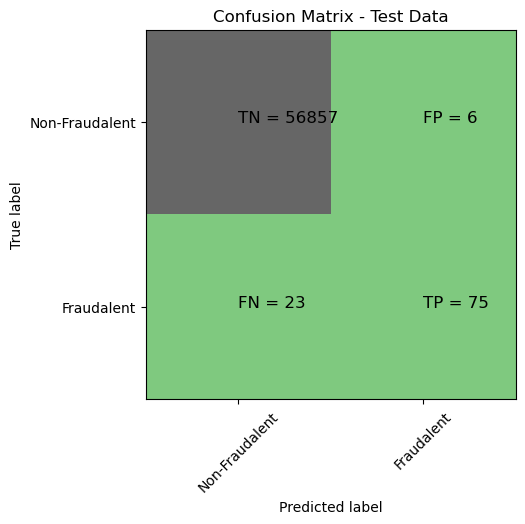

classification Report
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56863
           1       0.93      0.77      0.84        98

    accuracy                           1.00     56961
   macro avg       0.96      0.88      0.92     56961
weighted avg       1.00      1.00      1.00     56961

Random Forest roc_value: 0.9653785665295784
Random Forest threshold: 0.05
ROC for the test dataset 96.5%


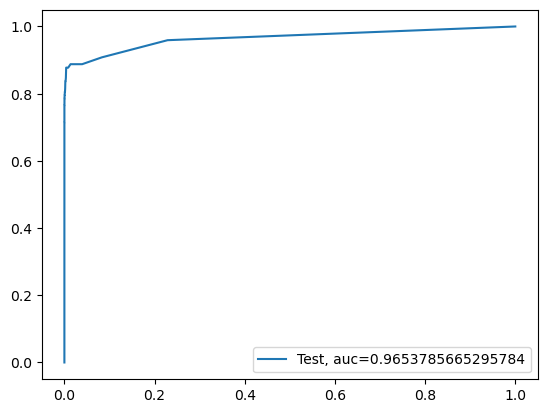

Time Taken by Model: --- 177.14975500106812 seconds ---
------------------------------------------------------------
XGBoost Model
Model Accuracy: 0.9993328768806727
Confusion Matirx


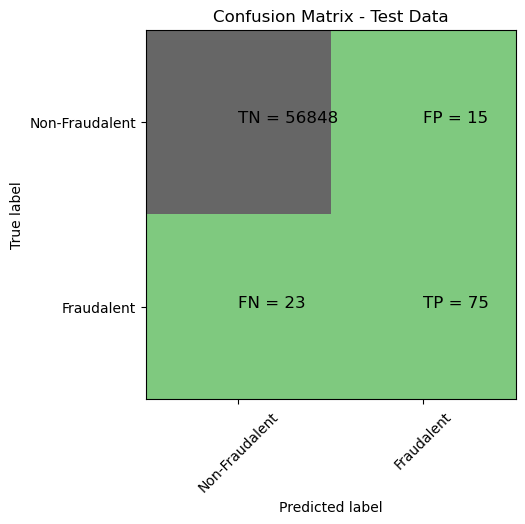

Classification Report
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56863
           1       0.83      0.77      0.80        98

    accuracy                           1.00     56961
   macro avg       0.92      0.88      0.90     56961
weighted avg       1.00      1.00      1.00     56961

XGboost roc_value: 0.9718047710088731
XGBoost threshold: 0.000216538057429716
ROC for the test dataset 97.2%


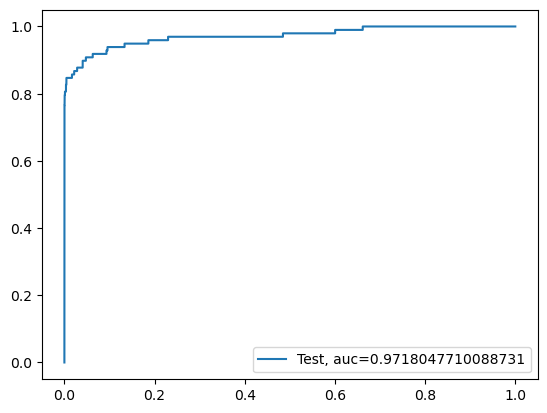

Time Taken by Model: --- 0.8593349456787109 seconds ---
------------------------------------------------------------


In [47]:
Data_Imbalance_Handiling = "SMOTE Oversampling with StratifiedKFold CV"
#Run Logistic Regression with L1 and L2 Regularisation
print("Logistic Regression with L1 and L2 Regularisation")
start_time = time.time()
df_Results = buildAndRunLogisticModels(df_Results, Data_Imbalance_Handiling, X_train_Smote, y_train_Smote, X_test, y_test)
print("Time Taken by Model: --- %s seconds ---" % (time.time() - start_time))
print('-'*60)

#Run KNN Model
print("KNN Model")
start_time = time.time()
df_Results = buildAndRunKNNModels(df_Results, Data_Imbalance_Handiling, X_train_Smote, y_train_Smote, X_test, y_test)
print("Time Taken by Model: --- %s seconds ---" % (time.time() - start_time))
print('-'*60)

#Run Decision tree models with 'gini' & 'entropy' criteria
print("Decision tree models with 'gini' & 'entropy' criteria")
start_time = time.time()
df_Results = buildAndRunTreeModels(df_Results, Data_Imbalance_Handiling, X_train_Smote, y_train_Smote, X_test, y_test)
print("Time Taken by Model: --- %s seconds ---" % (time.time() - start_time))
print('-'*60)

#Run Random Forest Model
print("Random Forest Model")
start_time = time.time()
df_Results = buildAndRunRandomForestModels(df_Results, Data_Imbalance_Handiling, X_train_Smote, y_train_Smote, X_test, y_test)
print("Time Taken by Model: --- %s seconds ---" % (time.time() - start_time))
print('-'*60)

#Run XGBoost Model
print("XGBoost Model")
start_time = time.time()
df_Results = buildAndRunXGBoostModels(df_Results, Data_Imbalance_Handiling, X_train_Smote, y_train_Smote, X_test, y_test)
print("Time Taken by Model: --- %s seconds ---" % (time.time() - start_time))
print('-'*60)

In [60]:
# Checking the df_result dataframe which contains consolidated results of all the runs
df_Results

,Methodology,Model,Accuracy,roc_value,threshold
0,Baseline,Logistic Regression with L2 Regularisation,0.998227,0.561048,0.499195
1,Baseline,Logistic Regression with L1 Regularisation,0.998227,0.561048,0.047390
2,RepeatedKFold Cross Validation,KNN,0.999140,0.871042,0.200000
3,RepeatedKFold Cross Validation,Tree Model with gini criteria,0.999052,0.866099,1.000000
4,RepeatedKFold Cross Validation,Random Forest,0.999508,0.943939,0.020000
5,RepeatedKFold Cross Validation,XGBoost,0.999315,0.912007,0.000178
6,RepeatedKFold Cross Validation,SVM,0.998350,0.505859,0.001787
7,Baseline,Logistic Regression with L2 Regularisation,0.998280,0.611162,0.499392
8,Baseline,Logistic Regression with L1 Regularisation,0.998280,0.611162,0.021087
9,StratifiedKFold Cross Validation,KNN,0.999192,0.805746,0.200000


# Results for SMOTE Oversampling with StatifiedKFold:
## Looking at Accuracy and ROC value....

# Oversampling with ADASYN Oversampling
### We will use ADASYN Oversampling mmethod to handle the class imbalance

In [49]:
# Creating dataframe with ADASYN and StratifiedKFold
from sklearn.model_selection import StratifiedKFold
from imblearn import over_sampling

skf = StratifiedKFold(n_splits=5, random_state=None)

for fold, (train_index, test_index) in enumerate(skf.split(X,y), 1):
    X_train = X.loc[train_index]
    y_train = y.loc[train_index]
    X_test = X.loc[test_index]
    y_test = y.loc[test_index]
    ADASYN = over_sampling.ADASYN(random_state=0)
    X_train_ADASYN, y_train_ADASYN = ADASYN.fit_resample(X_train, y_train)

X_train_ADASYN = pd.DataFrame(data=X_train_ADASYN, columns=cols)  

Logistic Regression with L1 and L2 Regularisation
Max auc_roc for l1: 0.5
Max auc_roc for l2: 0.6091741619819793
Parameters for l1 regularisations
[[0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
  0. 0. 0. 0. 0. 0.]]
[0.]
{np.int64(1): array([[0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5,
        0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5],
       [0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5,
        0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5],
       [0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5,
        0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5],
       [0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5,
        0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5],
       [0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5,
        0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5],
       [0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5,
        0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5],
       [0.5, 0.5, 0.5, 0.5, 0.5, 0.5

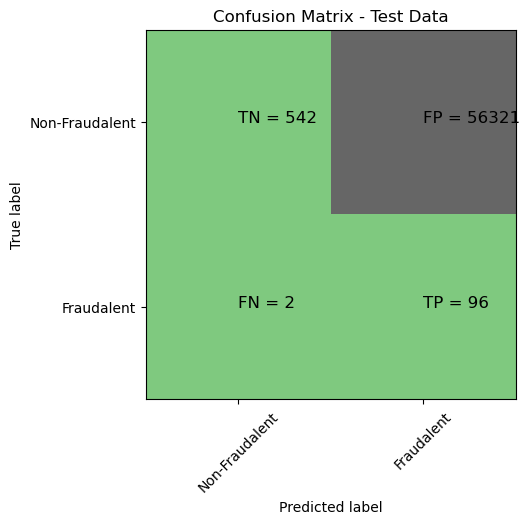

classification Report
              precision    recall  f1-score   support

           0       1.00      0.01      0.02     56863
           1       0.00      0.98      0.00        98

    accuracy                           0.01     56961
   macro avg       0.50      0.49      0.01     56961
weighted avg       0.99      0.01      0.02     56961

Accuracy pf Logistic model with l1 regularisation : 0.9982795245869981
Confusion Matrix


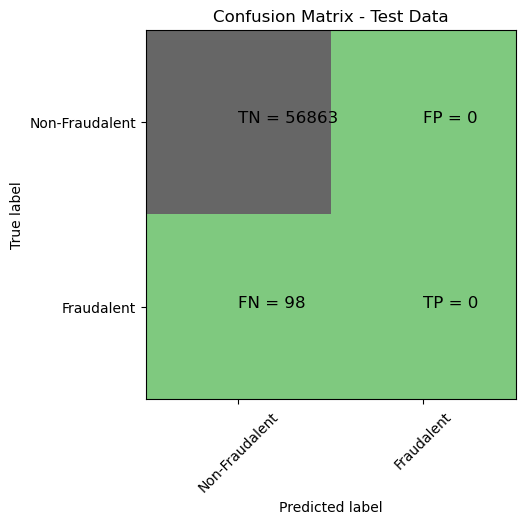

classification Report
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56863
           1       0.00      0.00      0.00        98

    accuracy                           1.00     56961
   macro avg       0.50      0.50      0.50     56961
weighted avg       1.00      1.00      1.00     56961

l2 roc_value: 0.4511041037768184
l2 threshold: 0.5762819111863179
ROC for the test dataset 45.1%


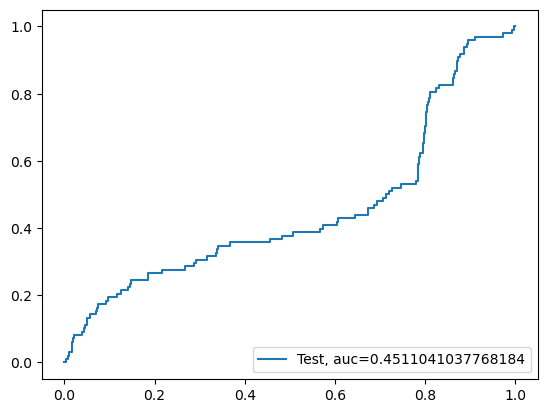

l1 roc_value: 0.5
l1 threshold: inf
ROC for the test dataset 50.0%


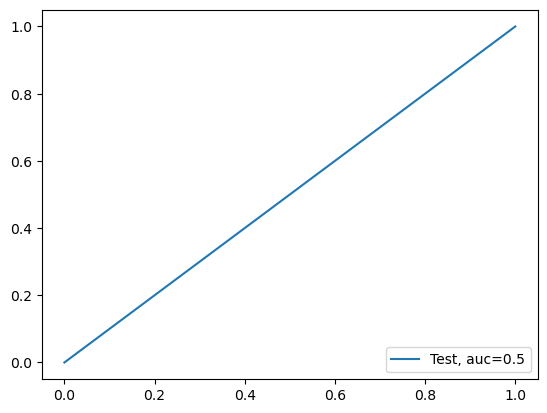

Time Taken by Model: --- 27.76988983154297 seconds ---
------------------------------------------------------------
KNN Model
model score
0.9945050122013307
Confusion Matrix


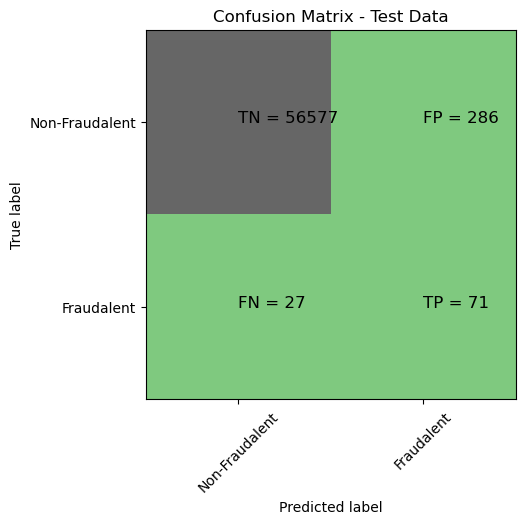

Classification Report
              precision    recall  f1-score   support

           0       1.00      0.99      1.00     56863
           1       0.20      0.72      0.31        98

    accuracy                           0.99     56961
   macro avg       0.60      0.86      0.65     56961
weighted avg       1.00      0.99      1.00     56961

KNN roc_value: 0.8601937811862167
KNN threshold: 0.6
ROC for the test dataset 86.0%


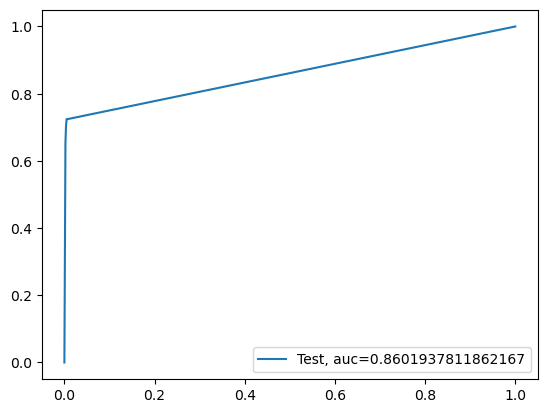

Time Taken by Model: --- 35.490466833114624 seconds ---
------------------------------------------------------------
Decision tree models with 'gini' & 'entropy' criteria
gini score: 0.9979635188988958
Confusion Matrix


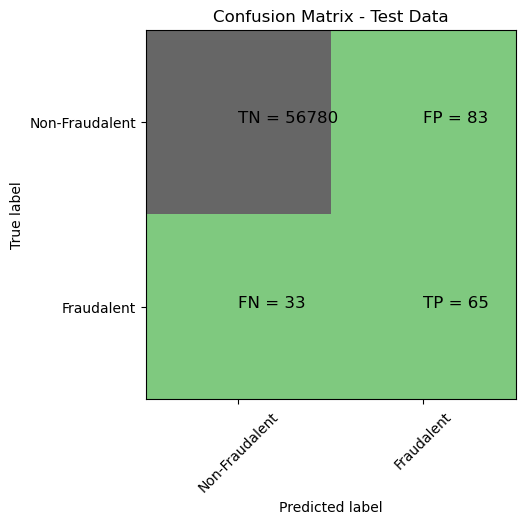

classification Report
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56863
           1       0.44      0.66      0.53        98

    accuracy                           1.00     56961
   macro avg       0.72      0.83      0.76     56961
weighted avg       1.00      1.00      1.00     56961

gini tree_roc_value: 0.8309028287466438
Tree threshold: 1.0
ROC for the test dataset 83.1%


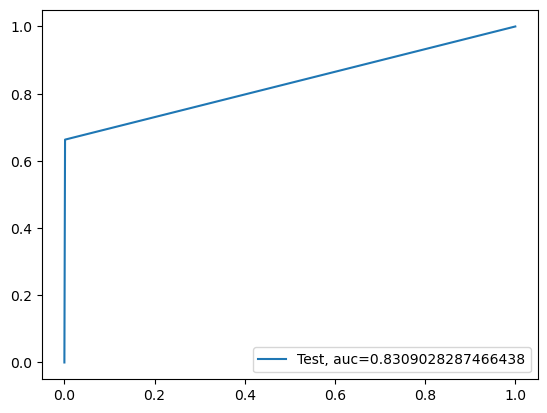

Time Taken by Model: --- 21.91265892982483 seconds ---
------------------------------------------------------------
Random Forest Model
Mocel Accuracy: 0.9995259914678464
Confusion Matrix


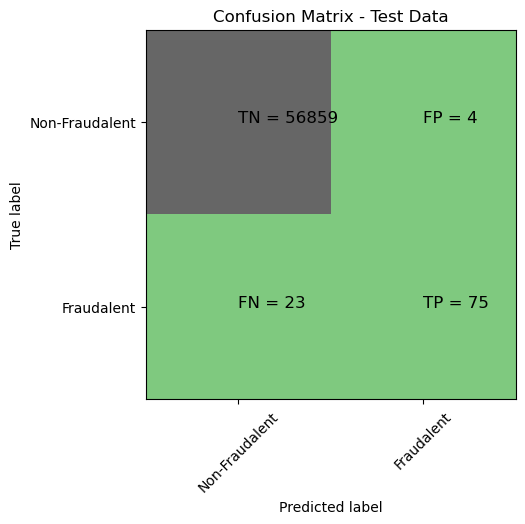

classification Report
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56863
           1       0.95      0.77      0.85        98

    accuracy                           1.00     56961
   macro avg       0.97      0.88      0.92     56961
weighted avg       1.00      1.00      1.00     56961

Random Forest roc_value: 0.9632665263843961
Random Forest threshold: 0.03
ROC for the test dataset 96.3%


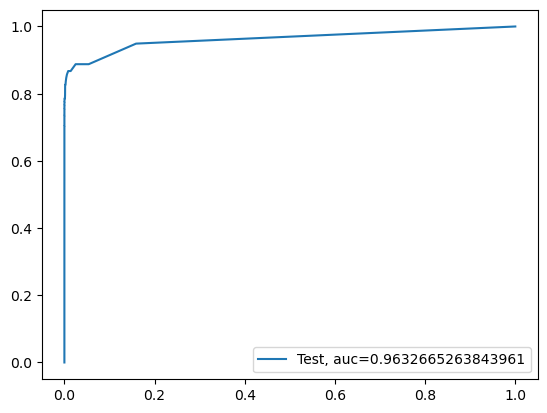

Time Taken by Model: --- 181.46332812309265 seconds ---
------------------------------------------------------------
XGBoost Model
Model Accuracy: 0.9993153210091115
Confusion Matirx


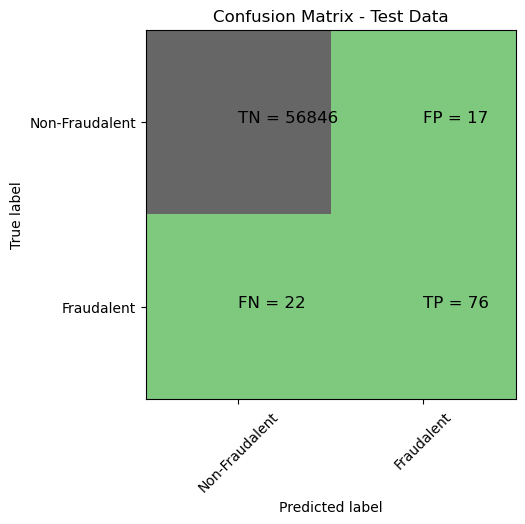

Classification Report
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56863
           1       0.82      0.78      0.80        98

    accuracy                           1.00     56961
   macro avg       0.91      0.89      0.90     56961
weighted avg       1.00      1.00      1.00     56961

XGboost roc_value: 0.9685077308977862
XGBoost threshold: 0.0006255550542846322
ROC for the test dataset 96.9%


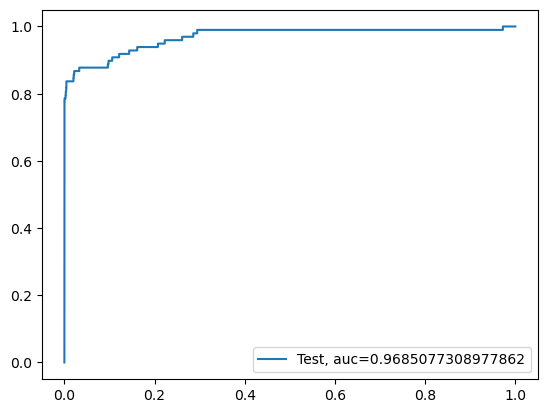

Time Taken by Model: --- 0.8399908542633057 seconds ---
------------------------------------------------------------


In [50]:
Data_Imbalance_Handiling = "ADASYN Oversampling with StratifiedKFold CV"
#Run Logistic Regression with L1 and L2 Regularisation
print("Logistic Regression with L1 and L2 Regularisation")
start_time = time.time()
df_Results = buildAndRunLogisticModels(df_Results, Data_Imbalance_Handiling, X_train_ADASYN, y_train_ADASYN, X_test, y_test)
print("Time Taken by Model: --- %s seconds ---" % (time.time() - start_time))
print('-'*60)

#Run KNN Model
print("KNN Model")
start_time = time.time()
df_Results = buildAndRunKNNModels(df_Results, Data_Imbalance_Handiling, X_train_ADASYN, y_train_ADASYN, X_test, y_test)
print("Time Taken by Model: --- %s seconds ---" % (time.time() - start_time))
print('-'*60)

#Run Decision tree models with 'gini' & 'entropy' criteria
print("Decision tree models with 'gini' & 'entropy' criteria")
start_time = time.time()
df_Results = buildAndRunTreeModels(df_Results, Data_Imbalance_Handiling, X_train_ADASYN, y_train_ADASYN, X_test, y_test)
print("Time Taken by Model: --- %s seconds ---" % (time.time() - start_time))
print('-'*60)

#Run Random Forest Model
print("Random Forest Model")
start_time = time.time()
df_Results = buildAndRunRandomForestModels(df_Results, Data_Imbalance_Handiling, X_train_ADASYN, y_train_ADASYN, X_test, y_test)
print("Time Taken by Model: --- %s seconds ---" % (time.time() - start_time))
print('-'*60)

#Run XGBoost Model
print("XGBoost Model")
start_time = time.time()
df_Results = buildAndRunXGBoostModels(df_Results, Data_Imbalance_Handiling, X_train_ADASYN, y_train_ADASYN, X_test, y_test)
print("Time Taken by Model: --- %s seconds ---" % (time.time() - start_time))
print('-'*60)

In [51]:
# Checking the df_result dataframe which contains consolidated results of all the runs
df_Results

,Methodology,Model,Accuracy,roc_value,threshold
0,Baseline,Logistic Regression with L2 Regularisation,0.998227,0.561048,0.499195
1,Baseline,Logistic Regression with L1 Regularisation,0.998227,0.561048,0.047390
2,RepeatedKFold Cross Validation,KNN,0.999140,0.871042,0.200000
3,RepeatedKFold Cross Validation,Tree Model with gini criteria,0.999052,0.866099,1.000000
4,RepeatedKFold Cross Validation,Random Forest,0.999508,0.943939,0.020000
5,RepeatedKFold Cross Validation,XGBoost,0.999315,0.912007,0.000178
6,RepeatedKFold Cross Validation,SVM,0.998350,0.505859,0.001787
7,Baseline,Logistic Regression with L2 Regularisation,0.998280,0.611162,0.499392
8,Baseline,Logistic Regression with L1 Regularisation,0.998280,0.611162,0.021087
9,StratifiedKFold Cross Validation,KNN,0.999192,0.805746,0.200000


# Results for ADASYN Oversampling with StratifiedKFold:

# Overall conclusion after running the models on Oversampled data
## Looking at the above results
## So we will try tume the hyperparameters of this model to get best results.

# Hyperparameter Tuning
# HPT- XGBoost Regression

In [52]:
# Performing Hyperparameter tuning
from xgboost.sklearn import XGBClassifier
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV
param_test = {
    'max_depth':range(3,20,2),
    'min_child_weight':range(1,6,2),
    'n_estimators':range(60,130,150),
    'learning_rate':[0.05,0.1,0.125,0.15,0.2],
    'gamma':[i/10.0 for i in range(0,5)],
    'subsample':[i/10.0 for i in range(7,10)],
    'colsample_bytree':[i/10.0 for i in range(7,10)]
}

gsearch1 = RandomizedSearchCV(estimator = XGBClassifier(base_score = 0.5, booster='gbtree', colsample_bylevel=1,
            colsample_bynode=1, max_delta_step=0,
            missing=None, n_jobs=-1,
            nthread=None, objective='binary:logistic', random_state=42,
            reg_alpha=0, reg_lambda=1, scale_pos_weight=1, seed=None,
            silent=None, verbosity=1),
            param_distributions = param_test, n_iter=5, scoring='roc_auc', n_jobs=-1, cv=5)

gsearch1.fit(X_over, y_over)
gsearch1.cv_results_ gsearch1.best_params_, gsearch1.best_score_    

##

In [55]:
# Creating XGBoost model with selected hyperparameters
from xgboost import XGBClassifier

clf = XGBClassifier(base_score=0.5, booster='gbtree', colsample_bylevel=1,
                    colsample_bynode=1, colsample_bytree=0.7, gamma=0.2,
                    learning_rate=0.125, max_delta_step=0, max_depth=7,
                    min_child_weight=5, n_estimators=60, n_jobs=1,
                    nthread=None, objective='binary:logistic', random_state=42,
                    reg_alpha=0, reg_lambda=1, scale_pos_weight=1, seed=None,
                    silent=None, subsample=0.8, verbosity=1)
#fit on the dataset
clf.fit(X_over, y_over )
XGB_test_score = clf.score(X_test, y_test)
print('Model Accuracy: {0}'.format(XGB_test_score))

# Probabilities for each class
XGB_probs = clf.predict_proba(X_test)[:, 1]

#Calculate roc auc

XGB_roc_value = roc_auc_score(y_test, XGB_probs)

print("XGB roc_value: {0}".format(XGB_roc_value))
fpr, tpr, thresholds = metrics.roc_curve(y_test, XGB_probs)
threshold = thresholds[np.argmax(tpr-fpr)]
print("XGBoost threshold: {0}".format(threshold))            

Model Accuracy: 0.9993679886237953
XGB roc_value: 0.9799479558279531
XGBoost threshold: 0.028758849948644638


# Print the important features of the model to understand the dataset

In [56]:
imp_var = []
for i in clf.feature_importances_:
    imp_var.append(i)
print('Top var = ', imp_var.index(np.sort(clf.feature_importances_)[-1])+1)
print('2nd Top var = ', imp_var.index(np.sort(clf.feature_importances_)[-2])+1)
print('3rd Top var = ', imp_var.index(np.sort(clf.feature_importances_)[-3])+1)

Top var =  14
2nd Top var =  17
3rd Top var =  10


In [57]:
# Calculate roc auc
XGB_roc_value = roc_auc_score(y_test, XGB_probs)

print("XGBoost roc_value: {0}".format(XGB_roc_value))
fpr, tpr, thresholds = metrics.roc_curve(y_test, XGB_probs)
threshold = thresholds[np.argmax(tpr-fpr)]
print("XGBoost threshold: {0}".format(threshold))

XGBoost roc_value: 0.9799479558279531
XGBoost threshold: 0.028758849948644638


# Conclusion
### In the oversample cases all of the models we build found that the XGBoost model with Random Oversampling with StratifiedKFold CV gave us the best accuracy and ROC on oversampled data, post that we performed hyperparameter tuning and got the below metrics.
### XGBoost roc_value: 0.9799479558279531
### XGBoost threshold: 0.028758849948644638